# **Proyecto para predicción de potencial emprendedor**

---



## **Librerías**

In [ ]:
# se utilizan para instalar bibliotecas en Python que permiten trabajar con todas las librerías que necesitamos
%pip install xlrd
%pip install openpyxl
%pip install factor-analyzer
%pip install scikit-learn-extra
%pip install semopy
%pip install --upgrade semopy

ERROR: Operation cancelled by user
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.8/42.8 kB 3.5 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for factor-analyzer: filename=factor_analyzer-0.5.1-py2.py3-none-any.whl size=42564 sha256=87124021a4f5c93776918509f914d028f509459f4f761802de2068b056a94bc4
  Stored in directory: /root/.cache/pip/wheels/24/59/82/6493618e30ed1cb7a013b9e1b0c9e17de80b04dfcef4ba8a4d
Successfully built factor-analyzer
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 56.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 41.7 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100.2/100.2 kB 8.7 MB/s eta 0:00:00
  Created wheel for semopy: filename=semopy-2.3.11-py3-none-any.whl size=1659682 sha256=b485cf8a99df3f2a54710f64e84d42d92336631bc212387ca2f700ee7dc0957c
  Stor

In [ ]:
# Importamos las librerías que vamos a utilizar en todo el proyecto
import pandas as pd
import os
import numpy as np
from datetime import timedelta, datetime, date
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import shapiro, kstest
from statsmodels.stats.outliers_influence import variance_inflation_factor
from semopy import Model, Optimizer, calc_stats

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from factor_analyzer import FactorAnalyzer, calculate_kmo, calculate_bartlett_sphericity
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.cluster import DBSCAN
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score
from mpl_toolkits.mplot3d import Axes3D

## **Cargar datos**

In [ ]:
# Con la librería pandas leemos el csv del trabajo
data = pd.read_csv("/content/CSV Datos test.csv", encoding='UTF-8-SIG', sep=';')

data.head(5)

[Output eliminado por privacidad: mostraba datos crudos con cuasi-identificadores. Ver docs/diagnostico.md §2.5]


In [ ]:
# Para saber si tenemos valores nulos (NaN) en nuestras columnas
data.isnull().sum()

,0
Ciudad,0
Actualmente soy,0
"Número de años que lleva funcionando (Si es estudiante y no tiene empresa, por favor escribir 0)",0
"Objeto social (negocio principal de la empresa) (Si es estudiante y no tiene empresa, por favor escribir NA)",0
Género,0
Rango de edad,0
Estado civil,0
Máximo nivel educativo terminado,0
Pregunta 1,0
Pregunta 2,0


In [ ]:
# Para tener información del dataframe y cada una de sus columnas
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 123 entries, 0 to 122
Data columns (total 27 columns):
 #   Column                                                                                                         Non-Null Count  Dtype  
---  ------                                                                                                         --------------  -----  
 0   Ciudad                                                                                                         123 non-null    object 
 1   Actualmente soy                                                                                                123 non-null    object 
 2   Número de años que lleva funcionando  (Si es estudiante y no tiene empresa, por favor escribir 0)              123 non-null    float64
 3   Objeto social (negocio principal de la empresa)  (Si es estudiante y no tiene empresa, por favor escribir NA)  123 non-null    object 
 4   Género                                            

In [ ]:
# Para trabajar de manera mas sencilla con las columnas
ciudad  = data['Ciudad']
ocupacion = data['Actualmente soy']
años_funcionando = data['Número de años que lleva funcionando  (Si es estudiante y no tiene empresa, por favor escribir 0)']
objeto_social = data['Objeto social (negocio principal de la empresa)  (Si es estudiante y no tiene empresa, por favor escribir NA)']
Género = data['Género']
Rango_de_edad = data['Rango de edad']
Estado_civil = data['Estado civil']
Maximo_nivel_educativo = data['Máximo nivel educativo terminado ']
Pregunta_1  = data['Pregunta 1 ']
Pregunta_2 = data['Pregunta 2']
Pregunta_3 = data['Pregunta 3']
Pregunta_4 = data['Pregunta 4']
Pregunta_5 = data['Pregunta 5']
Pregunta_6 = data['Pregunta 6']
Pregunta_7 = data['Pregunta 7']
Pregunta_8 = data['Pregunta 8']
Pregunta_9 = data['Pregunta 9']
Pregunta_10 = data['Pregunta 10']
Pregunta_11 = data['Pregunta 11']
Pregunta_12  = data['Pregunta 12']
Pregunta_13 = data['Pregunta 13']
Pregunta_14 = data['Pregunta 14']
Pregunta_15 = data['Pregunta 15']
Pregunta_16 = data['Pregunta 16']
Pregunta_17 = data['Pregunta 17']
Pregunta_18 = data['Pregunta 18']
Pregunta_19 = data['Pregunta 19']

## **Validación de los datos, tamaño de muestras, Valor P individual y Normalidad**

In [ ]:
print("Pregunta 1")
# Aplicamos la prueba de Shapiro-Wilk para una variable
stat, p_value = shapiro(data['Pregunta 1 '])
print(f'Statistics={stat}, p={p_value}')

# Verificamos si los datos son normales
if p_value > 0.05:
    print("Los datos tienen una distribución normal")
else:
    print("Los datos no tienen una distribución normal")

# Tamaño de muestra
z = 1.96  # Valor de Z para un nivel de confianza del 95%
precision = 0.5  # Precisión deseada

# Calculamos la desviación estándar (s) de la columna
s = data['Pregunta 1 '].std()

# Calculamos el tamaño de muestra
tamano_muestra = (z * s / (1 - precision)) ** 2

print(f"Tamaño de muestra ideal (D={precision}, Z={z}): {tamano_muestra}")

Pregunta 1
Statistics=0.7064100123928737, p=2.3088947983522866e-14
Los datos no tienen una distribución normal
Tamaño de muestra ideal (D=0.5, Z=1.96): 11.999431907237124


In [ ]:
print("Pregunta 2")
# Aplicamos la prueba de Shapiro-Wilk para una variable
stat, p_value = shapiro(data['Pregunta 2'])
print(f'Statistics={stat}, p={p_value}')

# Verificamos si los datos son normales
if p_value > 0.05:
    print("Los datos tienen una distribución normal")
else:
    print("Los datos no tienen una distribución normal")

# Tamaño de muestra
z = 1.96  # Valor de Z para un nivel de confianza del 95%
precision = 0.5  # Precisión deseada

# Calculamos la desviación estándar (s) de la columna
s = data['Pregunta 2'].std()

# Calculamos el tamaño de muestra
tamano_muestra = (z * s / (1 - precision)) ** 2

print(f"Tamaño de muestra ideal (D={precision}, Z={z}): {tamano_muestra}")

Pregunta 2
Statistics=0.7019428462793403, p=1.779522874075871e-14
Los datos no tienen una distribución normal
Tamaño de muestra ideal (D=0.5, Z=1.96): 15.698181527389039


In [ ]:
print("Pregunta 3")
# Aplicamos la prueba de Shapiro-Wilk para una variable
stat, p_value = shapiro(data['Pregunta 3'])
print(f'Statistics={stat}, p={p_value}')

# Verificamos si los datos son normales
if p_value > 0.05:
    print("Los datos tienen una distribución normal")
else:
    print("Los datos no tienen una distribución normal")

# Tamaño de muestra
z = 1.96  # Valor de Z para un nivel de confianza del 95%
precision = 0.5  # Precisión deseada

# Calculamos la desviación estándar (s) de la columna
s = data['Pregunta 3'].std()

# Calculamos el tamaño de muestra
tamano_muestra = (z * s / (1 - precision)) ** 2

print(f"Tamaño de muestra ideal (D={precision}, Z={z}): {tamano_muestra}")

Pregunta 3
Statistics=0.5882716536362625, p=5.1638214209923066e-17
Los datos no tienen una distribución normal
Tamaño de muestra ideal (D=0.5, Z=1.96): 12.185803012128487


In [ ]:
print("pregunta 4")
# Aplicamos la prueba de Shapiro-Wilk para una variable
stat, p_value = shapiro(data['Pregunta 4'])
print(f'Statistics={stat}, p={p_value}')

# Verificamos si los datos son normales
if p_value > 0.05:
    print("Los datos tienen una distribución normal")
else:
    print("Los datos no tienen una distribución normal")

# Tamaño de muestra
z = 1.96  # Valor de Z para un nivel de confianza del 95%
precision = 0.5  # Precisión deseada

# Calculamos la desviación estándar (s) de la columna
s = data['Pregunta 4'].std()

# Calculamos el tamaño de muestra
tamano_muestra = (z * s / (1 - precision)) ** 2

print(f"Tamaño de muestra ideal (D={precision}, Z={z}): {tamano_muestra}")

pregunta 4
Statistics=0.7445889796535271, p=2.419096760717847e-13
Los datos no tienen una distribución normal
Tamaño de muestra ideal (D=0.5, Z=1.96): 15.386880341196873


In [ ]:
print("pregunta 5")
# Aplicamos la prueba de Shapiro-Wilk para una variable
stat, p_value = shapiro(data['Pregunta 5'])
print(f'Statistics={stat}, p={p_value}')

# Verificamos si los datos son normales
if p_value > 0.05:
    print("Los datos tienen una distribución normal")
else:
    print("Los datos no tienen una distribución normal")

# Tamaño de muestra
z = 1.96  # Valor de Z para un nivel de confianza del 95%
precision = 0.5  # Precisión deseada

# Calculamos la desviación estándar (s) de la columna
s = data['Pregunta 5'].std()

# Calculamos el tamaño de muestra
tamano_muestra = (z * s / (1 - precision)) ** 2

print(f"Tamaño de muestra ideal (D={precision}, Z={z}): {tamano_muestra}")

pregunta 5
Statistics=0.8067941730145225, p=2.006433170222753e-11
Los datos no tienen una distribución normal
Tamaño de muestra ideal (D=0.5, Z=1.96): 26.9623691856591


In [ ]:
print("pregunta 6")
# Aplicamos la prueba de Shapiro-Wilk para una variable
stat, p_value = shapiro(data['Pregunta 6'])
print(f'Statistics={stat}, p={p_value}')

# Verificamos si los datos son normales
if p_value > 0.05:
    print("Los datos tienen una distribución normal")
else:
    print("Los datos no tienen una distribución normal")

# Tamaño de muestra
z = 1.96  # Valor de Z para un nivel de confianza del 95%
precision = 0.5  # Precisión deseada

# Calculamos la desviación estándar (s) de la columna
s = data['Pregunta 6'].std()

# Calculamos el tamaño de muestra
tamano_muestra = (z * s / (1 - precision)) ** 2

print(f"Tamaño de muestra ideal (D={precision}, Z={z}): {tamano_muestra}")

pregunta 6
Statistics=0.6453797371151442, p=8.1956908160514665e-16
Los datos no tienen una distribución normal
Tamaño de muestra ideal (D=0.5, Z=1.96): 13.623522964147686


In [ ]:
print("pregunta 7")
# Aplicamos la prueba de Shapiro-Wilk para una variable
stat, p_value = shapiro(data['Pregunta 7'])
print(f'Statistics={stat}, p={p_value}')

# Verificamos si los datos son normales
if p_value > 0.05:
    print("Los datos tienen una distribución normal")
else:
    print("Los datos no tienen una distribución normal")

# Tamaño de muestra
z = 1.96  # Valor de Z para un nivel de confianza del 95%
precision = 0.5  # Precisión deseada

# Calculamos la desviación estándar (s) de la columna
s = data['Pregunta 7'].std()

# Calculamos el tamaño de muestra
tamano_muestra = (z * s / (1 - precision)) ** 2

print(f"Tamaño de muestra ideal (D={precision}, Z={z}): {tamano_muestra}")

pregunta 7
Statistics=0.6269112479003648, p=3.241587766535884e-16
Los datos no tienen una distribución normal
Tamaño de muestra ideal (D=0.5, Z=1.96): 11.428030387844842


In [ ]:
print("pregunta 8")
# Aplicamos la prueba de Shapiro-Wilk para una variable
stat, p_value = shapiro(data['Pregunta 8'])
print(f'Statistics={stat}, p={p_value}')

# Verificamos si los datos son normales
if p_value > 0.05:
    print("Los datos tienen una distribución normal")
else:
    print("Los datos no tienen una distribución normal")

# Tamaño de muestra
z = 1.96  # Valor de Z para un nivel de confianza del 95%
precision = 0.5  # Precisión deseada

# Calculamos la desviación estándar (s) de la columna
s = data['Pregunta 8'].std()

# Calculamos el tamaño de muestra
tamano_muestra = (z * s / (1 - precision)) ** 2

print(f"Tamaño de muestra ideal (D={precision}, Z={z}): {tamano_muestra}")

pregunta 8
Statistics=0.7010479201726743, p=1.689628469167378e-14
Los datos no tienen una distribución normal
Tamaño de muestra ideal (D=0.5, Z=1.96): 14.102762948154057


In [ ]:
print("pregunta 9")
# Aplicamos la prueba de Shapiro-Wilk para una variable
stat, p_value = shapiro(data['Pregunta 9'])
print(f'Statistics={stat}, p={p_value}')

# Verificamos si los datos son normales
if p_value > 0.05:
    print("Los datos tienen una distribución normal")
else:
    print("Los datos no tienen una distribución normal")

# Tamaño de muestra
z = 1.96  # Valor de Z para un nivel de confianza del 95%
precision = 0.5  # Precisión deseada

# Calculamos la desviación estándar (s) de la columna
s = data['Pregunta 9'].std()

# Calculamos el tamaño de muestra
tamano_muestra = (z * s / (1 - precision)) ** 2

print(f"Tamaño de muestra ideal (D={precision}, Z={z}): {tamano_muestra}")

pregunta 9
Statistics=0.870671653607815, p=5.882138947506813e-09
Los datos no tienen una distribución normal
Tamaño de muestra ideal (D=0.5, Z=1.96): 21.696873463947757


In [ ]:
print("pregunta 10")
# Aplicamos la prueba de Shapiro-Wilk para una variable
stat, p_value = shapiro(data['Pregunta 10'])
print(f'Statistics={stat}, p={p_value}')

# Verificamos si los datos son normales
if p_value > 0.05:
    print("Los datos tienen una distribución normal")
else:
    print("Los datos no tienen una distribución normal")

# Tamaño de muestra
z = 1.96  # Valor de Z para un nivel de confianza del 95%
precision = 0.5  # Precisión deseada

# Calculamos la desviación estándar (s) de la columna
s = data['Pregunta 10'].std()

# Calculamos el tamaño de muestra
tamano_muestra = (z * s / (1 - precision)) ** 2

print(f"Tamaño de muestra ideal (D={precision}, Z={z}): {tamano_muestra}")

pregunta 10
Statistics=0.8412938270634134, p=3.584195333101317e-10
Los datos no tienen una distribución normal
Tamaño de muestra ideal (D=0.5, Z=1.96): 28.785119552179115


In [ ]:
print("pregunta 11")
# Aplicamos la prueba de Shapiro-Wilk para una variable
stat, p_value = shapiro(data['Pregunta 11'])
print(f'Statistics={stat}, p={p_value}')

# Verificamos si los datos son normales
if p_value > 0.05:
    print("Los datos tienen una distribución normal")
else:
    print("Los datos no tienen una distribución normal")

# Tamaño de muestra
z = 1.96  # Valor de Z para un nivel de confianza del 95%
precision = 0.5  # Precisión deseada

# Calculamos la desviación estándar (s) de la columna
s = data['Pregunta 11'].std()

# Calculamos el tamaño de muestra
tamano_muestra = (z * s / (1 - precision)) ** 2

print(f"Tamaño de muestra ideal (D={precision}, Z={z}): {tamano_muestra}")

pregunta 11
Statistics=0.878822223056117, p=1.371678982893875e-08
Los datos no tienen una distribución normal
Tamaño de muestra ideal (D=0.5, Z=1.96): 25.534889404238314


In [ ]:
print("pregunta 12")
# Aplicamos la prueba de Shapiro-Wilk para una variable
stat, p_value = shapiro(data['Pregunta 12'])
print(f'Statistics={stat}, p={p_value}')

# Verificamos si los datos son normales
if p_value > 0.05:
    print("Los datos tienen una distribución normal")
else:
    print("Los datos no tienen una distribución normal")

# Tamaño de muestra
z = 1.96  # Valor de Z para un nivel de confianza del 95%
precision = 0.5  # Precisión deseada

# Calculamos la desviación estándar (s) de la columna
s = data['Pregunta 12'].std()

# Calculamos el tamaño de muestra
tamano_muestra = (z * s / (1 - precision)) ** 2

print(f"Tamaño de muestra ideal (D={precision}, Z={z}): {tamano_muestra}")

pregunta 12
Statistics=0.8247733017640966, p=8.59910398271355e-11
Los datos no tienen una distribución normal
Tamaño de muestra ideal (D=0.5, Z=1.96): 29.805040543782447


In [ ]:
print("pregunta 13")
# Aplicamos la prueba de Shapiro-Wilk para una variable
stat, p_value = shapiro(data['Pregunta 13'])
print(f'Statistics={stat}, p={p_value}')

# Verificamos si los datos son normales
if p_value > 0.05:
    print("Los datos tienen una distribución normal")
else:
    print("Los datos no tienen una distribución normal")

# Tamaño de muestra
z = 1.96  # Valor de Z para un nivel de confianza del 95%
precision = 0.5  # Precisión deseada

# Calculamos la desviación estándar (s) de la columna
s = data['Pregunta 13'].std()

# Calculamos el tamaño de muestra
tamano_muestra = (z * s / (1 - precision)) ** 2

print(f"Tamaño de muestra ideal (D={precision}, Z={z}): {tamano_muestra}")

pregunta 13
Statistics=0.8744395959471121, p=8.663144584114858e-09
Los datos no tienen una distribución normal
Tamaño de muestra ideal (D=0.5, Z=1.96): 32.139799440223925


In [ ]:
print("pregunta 14")
# Aplicamos la prueba de Shapiro-Wilk para una variable
stat, p_value = shapiro(data['Pregunta 14'])
print(f'Statistics={stat}, p={p_value}')

# Verificamos si los datos son normales
if p_value > 0.05:
    print("Los datos tienen una distribución normal")
else:
    print("Los datos no tienen una distribución normal")

# Tamaño de muestra
z = 1.96  # Valor de Z para un nivel de confianza del 95%
precision = 0.5  # Precisión deseada

# Calculamos la desviación estándar (s) de la columna
s = data['Pregunta 14'].std()

# Calculamos el tamaño de muestra
tamano_muestra = (z * s / (1 - precision)) ** 2

print(f"Tamaño de muestra ideal (D={precision}, Z={z}): {tamano_muestra}")

pregunta 14
Statistics=0.6529692602685717, p=1.212148592875209e-15
Los datos no tienen una distribución normal
Tamaño de muestra ideal (D=0.5, Z=1.96): 13.605090657070484


In [ ]:
print("pregunta 15")
# Aplicamos la prueba de Shapiro-Wilk para una variable
stat, p_value = shapiro(data['Pregunta 15'])
print(f'Statistics={stat}, p={p_value}')

# Verificamos si los datos son normales
if p_value > 0.05:
    print("Los datos tienen una distribución normal")
else:
    print("Los datos no tienen una distribución normal")

# Tamaño de muestra
z = 1.96  # Valor de Z para un nivel de confianza del 95%
precision = 0.5  # Precisión deseada

# Calculamos la desviación estándar (s) de la columna
s = data['Pregunta 15'].std()

# Calculamos el tamaño de muestra
tamano_muestra = (z * s / (1 - precision)) ** 2

print(f"Tamaño de muestra ideal (D={precision}, Z={z}): {tamano_muestra}")

pregunta 15
Statistics=0.8240214802125083, p=8.07564886300254e-11
Los datos no tienen una distribución normal
Tamaño de muestra ideal (D=0.5, Z=1.96): 16.742678928428635


In [ ]:
print("pregunta 16")
# Aplicamos la prueba de Shapiro-Wilk para una variable
stat, p_value = shapiro(data['Pregunta 16'])
print(f'Statistics={stat}, p={p_value}')

# Verificamos si los datos son normales
if p_value > 0.05:
    print("Los datos tienen una distribución normal")
else:
    print("Los datos no tienen una distribución normal")

# Tamaño de muestra
z = 1.96  # Valor de Z para un nivel de confianza del 95%
precision = 0.5  # Precisión deseada

# Calculamos la desviación estándar (s) de la columna
s = data['Pregunta 16'].std()

# Calculamos el tamaño de muestra
tamano_muestra = (z * s / (1 - precision)) ** 2

print(f"Tamaño de muestra ideal (D={precision}, Z={z}): {tamano_muestra}")

pregunta 16
Statistics=0.8746862591068426, p=8.887753415970529e-09
Los datos no tienen una distribución normal
Tamaño de muestra ideal (D=0.5, Z=1.96): 24.234387738238045


In [ ]:
print("pregunta 17")
# Aplicamos la prueba de Shapiro-Wilk para una variable
stat, p_value = shapiro(data['Pregunta 17'])
print(f'Statistics={stat}, p={p_value}')

# Verificamos si los datos son normales
if p_value > 0.05:
    print("Los datos tienen una distribución normal")
else:
    print("Los datos no tienen una distribución normal")

# Tamaño de muestra
z = 1.96  # Valor de Z para un nivel de confianza del 95%
precision = 0.5  # Precisión deseada

# Calculamos la desviación estándar (s) de la columna
s = data['Pregunta 17'].std()

# Calculamos el tamaño de muestra
tamano_muestra = (z * s / (1 - precision)) ** 2

print(f"Tamaño de muestra ideal (D={precision}, Z={z}): {tamano_muestra}")

pregunta 17
Statistics=0.90438911353972, p=2.5111877248530227e-07
Los datos no tienen una distribución normal
Tamaño de muestra ideal (D=0.5, Z=1.96): 24.103313554578172


In [ ]:
print("pregunta 18")
# Aplicamos la prueba de Shapiro-Wilk para una variable
stat, p_value = shapiro(data['Pregunta 18'])
print(f'Statistics={stat}, p={p_value}')

# Verificamos si los datos son normales
if p_value > 0.05:
    print("Los datos tienen una distribución normal")
else:
    print("Los datos no tienen una distribución normal")

# Tamaño de muestra
z = 1.96  # Valor de Z para un nivel de confianza del 95%
precision = 0.5  # Precisión deseada

# Calculamos la desviación estándar (s) de la columna
s = data['Pregunta 18'].std()

# Calculamos el tamaño de muestra
tamano_muestra = (z * s / (1 - precision)) ** 2

print(f"Tamaño de muestra ideal (D={precision}, Z={z}): {tamano_muestra}")

pregunta 18
Statistics=0.8906619998932532, p=5.0083342818527234e-08
Los datos no tienen una distribución normal
Tamaño de muestra ideal (D=0.5, Z=1.96): 26.077618445954947


In [ ]:
print("pregunta 19")
# Aplicamos la prueba de Shapiro-Wilk para una variable
stat, p_value = shapiro(data['Pregunta 19'])
print(f'Statistics={stat}, p={p_value}')

# Verificamos si los datos son normales
if p_value > 0.05:
    print("Los datos tienen una distribución normal")
else:
    print("Los datos no tienen una distribución normal")

# Tamaño de muestra
z = 1.96  # Valor de Z para un nivel de confianza del 95%
precision = 0.5  # Precisión deseada

# Calculamos la desviación estándar (s) de la columna
s = data['Pregunta 19'].std()

# Calculamos el tamaño de muestra
tamano_muestra = (z * s / (1 - precision)) ** 2

print(f"Tamaño de muestra ideal (D={precision}, Z={z}): {tamano_muestra}")

pregunta 19
Statistics=0.8883496352410623, p=3.8639020024087545e-08
Los datos no tienen una distribución normal
Tamaño de muestra ideal (D=0.5, Z=1.96): 24.990112328401974


Con estos resultados podemos observar que los datos no siguen una distribución normal ya que por lo observado en el análisis descriptivo tiene un comportamiento exponencial. Así mismo podemos ver que el tamaño de muestra con los cada pregunta está dentro del rango de respuestas que poseemos donde el menor tamaño de muestra es 12 y el mayor 33

## **Estadísticas de validación**

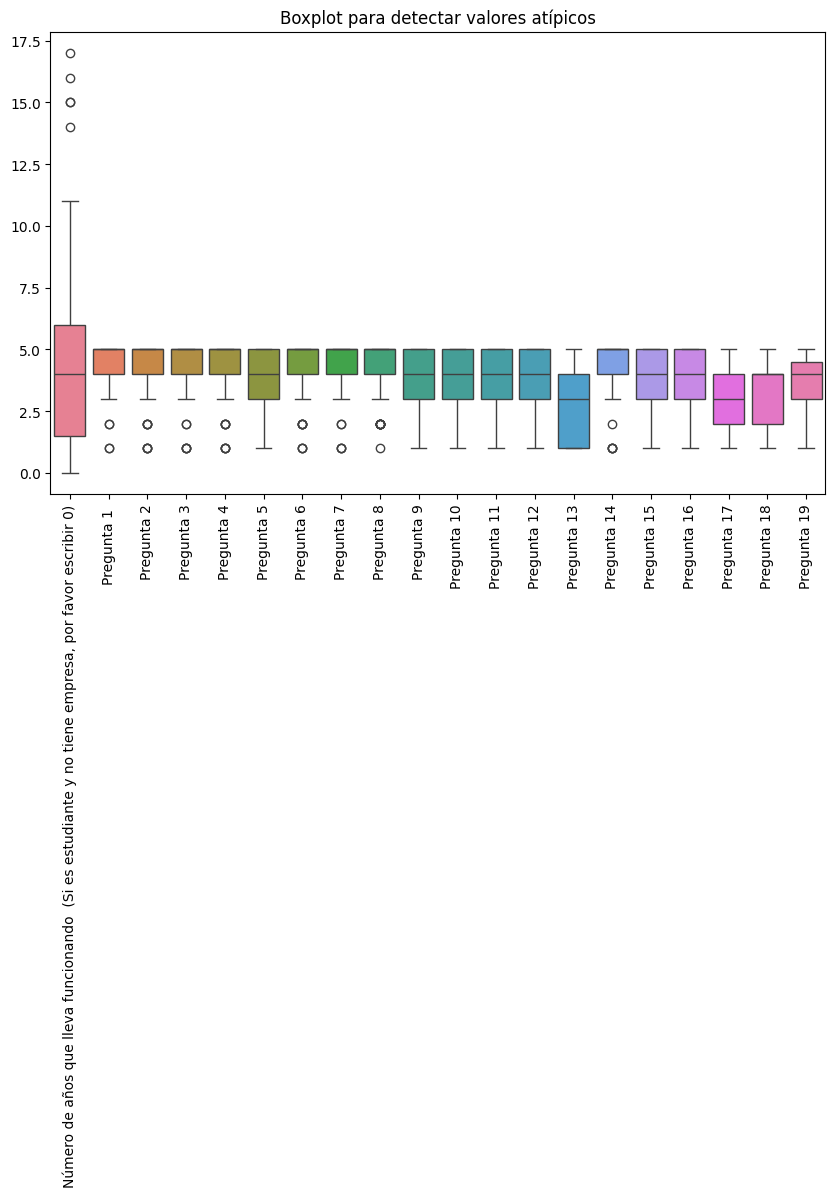

In [ ]:
# Creamos un gráfico de caja para ver los outliers

plt.figure(figsize=(10, 6))
sns.boxplot(data=data)
plt.title('Boxplot para detectar valores atípicos')

# Rotar las etiquetas horizontales a 90 grados
plt.xticks(rotation=90)

plt.show()

In [ ]:
# Calculamos el VIF para todas las variables

variables = data[['Pregunta 1 ', 'Pregunta 2', 'Pregunta 3','Pregunta 4','Pregunta 5','Pregunta 6','Pregunta 7','Pregunta 8','Pregunta 9','Pregunta 10','Pregunta 11','Pregunta 12','Pregunta 13','Pregunta 14','Pregunta 15','Pregunta 16','Pregunta 17','Pregunta 18','Pregunta 19']]
vif_data = pd.DataFrame()
vif_data['Feature'] = variables.columns
vif_data['VIF'] = [variance_inflation_factor(variables.values, i) for i in range(len(variables.columns))]

print(vif_data)

        Feature         VIF
0   Pregunta 1    52.690851
1    Pregunta 2   50.219621
2    Pregunta 3   79.908818
3    Pregunta 4   56.575339
4    Pregunta 5   18.796952
5    Pregunta 6   92.787120
6    Pregunta 7  104.171006
7    Pregunta 8   69.461626
8    Pregunta 9   33.433427
9   Pregunta 10   48.500449
10  Pregunta 11   22.126899
11  Pregunta 12   34.217261
12  Pregunta 13   10.375758
13  Pregunta 14   53.161857
14  Pregunta 15   40.595299
15  Pregunta 16   22.203111
16  Pregunta 17   17.288737
17  Pregunta 18   21.830867
18  Pregunta 19   18.499807


In [ ]:
# Consistencia interna

# Datos de ejemplo con las preguntas
preguntas = ['Pregunta 1 ', 'Pregunta 2', 'Pregunta 3', 'Pregunta 4', 'Pregunta 5',
             'Pregunta 6', 'Pregunta 7', 'Pregunta 8', 'Pregunta 9', 'Pregunta 10',
             'Pregunta 11', 'Pregunta 12', 'Pregunta 13', 'Pregunta 14', 'Pregunta 15',
             'Pregunta 16', 'Pregunta 17', 'Pregunta 18', 'Pregunta 19']


data_preguntas = data[preguntas]

# Creamos la función para calcular el Alfa de Cronbach
def alpha_de_cronbach(data):
    # Número de ítems (preguntas)
    items = data_preguntas.shape[1]

    # Varianza total de los puntajes (suma de las columnas)
    varianza_total = data_preguntas.sum(axis=1).var()

    # Varianza de cada ítem
    varianza_item = data_preguntas.var(axis=0)

    # Cálculo del Alfa de Cronbach
    cronbach_alpha = (items / (items - 1)) * (1 - varianza_item.sum() / varianza_total)

    return cronbach_alpha

alpha = alpha_de_cronbach(data_preguntas)

# Mostramos el valor del Alfa de Cronbach
print(f'Alfa de Cronbach: {alpha}')

Alfa de Cronbach: 0.9112738679367456


Con un valor de 0.911, se puede concluir que las preguntas de nuestro constructo están muy bien diseñadas y están midiendo de manera coherente un concepto en común (como una dimensión del emprendimiento o un factor relacionado). Esto significa que el cuestionario es confiable para evaluar ese concepto.

In [ ]:
# Cálculo de la prueba Kaiser-Meyer-Olkin (KMO)

kmo_all, kmo_model = calculate_kmo(data_preguntas)
print(f"KMO individual: {kmo_all}")
print(f"KMO general: {kmo_model}")

KMO individual: [0.91702257 0.85364223 0.85333507 0.91502385 0.86914204 0.8010802
 0.77055808 0.9222268  0.88854245 0.84596777 0.84476937 0.88201347
 0.87690537 0.85789735 0.73140911 0.77401504 0.8720287  0.78034176
 0.79138161]
KMO general: 0.850168108338055


Con un valor de 0.85 y con los valores individuales todos por encima del 0.75 podemos concluir que los datos son adecuados para un análisis factorial

In [ ]:
# Cálculo de esfericidad de Bartlett

chi_square_value, p_value = calculate_bartlett_sphericity(data_preguntas)
print(f"Chi-cuadrado: {chi_square_value}")
print(f"p-valor: {p_value}")

Chi-cuadrado: 1479.751887744332
p-valor: 4.875469321830849e-207


Dado que el p-valor es muy pequeño, se puede interpretar que sí hay correlaciones significativas entre las variables, lo que significa que es adecuado realizar un análisis factorial en el conjunto de datos. En resumen, la prueba de esfericidad de Bartlett indica que se puedes continuar con el análisis factorial, ya que los datos son aptos para ello.

## **Análisis de estadísticas descriptivas**

In [ ]:
# Estadísticas generales del dataset (Sólo valores numéricos)
data.describe()

,"Número de años que lleva funcionando (Si es estudiante y no tiene empresa, por favor escribir 0)",Pregunta 1,Pregunta 2,Pregunta 3,Pregunta 4,Pregunta 5,Pregunta 6,Pregunta 7,Pregunta 8,Pregunta 9,Pregunta 10,Pregunta 11,Pregunta 12,Pregunta 13,Pregunta 14,Pregunta 15,Pregunta 16,Pregunta 17,Pregunta 18,Pregunta 19
count,123.000000,123.000000,123.000000,123.000000,123.000000,123.000000,123.000000,123.000000,123.000000,123.000000,123.000000,123.000000,123.000000,123.000000,123.000000,123.000000,123.000000,123.000000,123.000000,123.000000
mean,4.350407,4.390244,4.317073,4.504065,4.235772,3.821138,4.430894,4.487805,4.349593,3.691057,3.634146,3.512195,3.682927,2.878049,4.422764,3.975610,3.552846,3.146341,3.382114,3.447154
std,3.707002,0.883678,1.010738,0.890515,1.000666,1.324625,0.941583,0.862382,0.958001,1.188263,1.368667,1.289083,1.392704,1.446224,0.940946,1.043822,1.255827,1.252427,1.302710,1.275258
min,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
25%,1.500000,4.000000,4.000000,4.000000,4.000000,3.000000,4.000000,4.000000,4.000000,3.000000,3.000000,3.000000,3.000000,1.000000,4.000000,3.000000,3.000000,2.000000,2.000000,3.000000
50%,4.000000,5.000000,5.000000,5.000000,5.000000,4.000000,5.000000,5.000000,5.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,4.000000,4.000000,3.000000,4.000000,4.000000
75%,6.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,4.000000,5.000000,5.000000,5.000000,4.000000,4.000000,4.500000
max,17.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000


In [ ]:
# Estadísticas valores cualitativos

# Proporción ciudad en la base de datos
print(ciudad.value_counts())

[Output eliminado por privacidad: mostraba datos crudos con cuasi-identificadores. Ver docs/diagnostico.md §2.5]


In [ ]:
# proporción de ocupación en la base de datos
emprendedor = 0
estudiante = 0
ambos = 0
for i in ocupacion:
  if i == 'Emprendedor (a)':
    emprendedor += 1
  else:
    ambos += 1
print(f'En total la base de datos cuenta con {emprendedor} emprendedores, lo cual es {100*(emprendedor/123):.2f}% del total de colaboradores')
print(f'En total la base de datos cuenta con {ambos} estudiantes y emprendedores,lo cual es {100*(ambos/123):.2f}% del total de colaboradores')

En total la base de datos cuenta con 102 emprendedores, lo cual es 82.93% del total de colaboradores
En total la base de datos cuenta con 21 estudiantes y emprendedores,lo cual es 17.07% del total de colaboradores


In [ ]:
# proporción de hombres y mujeres en la base de datos
hombres = 0
mujeres = 0
for i in Género:
  if i == 'Masculino':
    hombres += 1
  elif i == 'Femenino':
    mujeres += 1

print(f"En total la base de datos cuenta con {hombres} colaboradores masculinos, lo cual es {100*(hombres/123)}% del total de colaboradores")
print(f"En total la base de datos cuenta con {mujeres} colaboradores femeninos, lo cual es {100*(mujeres/123)}% del total de colaboradores")

En total la base de datos cuenta con 56 colaboradores masculinos, lo cual es 45.52845528455284% del total de colaboradores
En total la base de datos cuenta con 67 colaboradores femeninos, lo cual es 54.47154471544715% del total de colaboradores


In [ ]:
# proporción de rango de edad
print(Rango_de_edad.value_counts())

Rango de edad
Entre 25 y 35 años    40
Entre 35 y 45 años    35
Entre 45 y 55 años    29
Más de 55 años        12
Menos de 25 años       7
Name: count, dtype: int64


In [ ]:
# proporción estado civil
soltero = 0
casado = 0
otro = 0
for i in Estado_civil:
  if i == 'Soltera (o)':
    soltero += 1
  elif i == 'Casada (o)':
    casado += 1
  else:
    otro += 1
print(f"En total la base de datos cuenta con {soltero} colaboradores solteros, lo cual es {100*(soltero/123):.2f}% del total de colaboradores")
print(f"En total la base de datos cuenta con {casado} colaboradores casados, lo cual es {100*(casado/123):.2f}% del total de colaboradores")
print(f"En total la base de datos cuenta con {otro} colaboradores en otra situación de estado civil, lo cual es {100*(otro/123):.2f}% del total de colaboradores")

En total la base de datos cuenta con 66 colaboradores solteros, lo cual es 53.66% del total de colaboradores
En total la base de datos cuenta con 38 colaboradores casados, lo cual es 30.89% del total de colaboradores
En total la base de datos cuenta con 19 colaboradores en otra situación de estado civil, lo cual es 15.45% del total de colaboradores


In [ ]:
# proporción máximo nivel educativo terminado
print(Maximo_nivel_educativo.value_counts())

Máximo nivel educativo terminado 
Universitaria      36
Técnica            24
Especialización    19
Tecnología         15
Maestría           12
Bachillerato       12
Doctorado           4
Primaria            1
Name: count, dtype: int64


##  **Análisis Factorial Exploratorio**

### **Matriz de correlaciones**

La matriz de correlaciones es una tabla que muestra la relación entre cada par de variables en un conjunto de datos. Cada celda de la matriz contiene el coeficiente de correlación entre dos variables, que puede variar entre -1 (correlación perfecta negativa) y 1 (correlación perfecta positiva). La matriz de correlaciones es una herramienta útil para identificar patrones y relaciones entre variables.

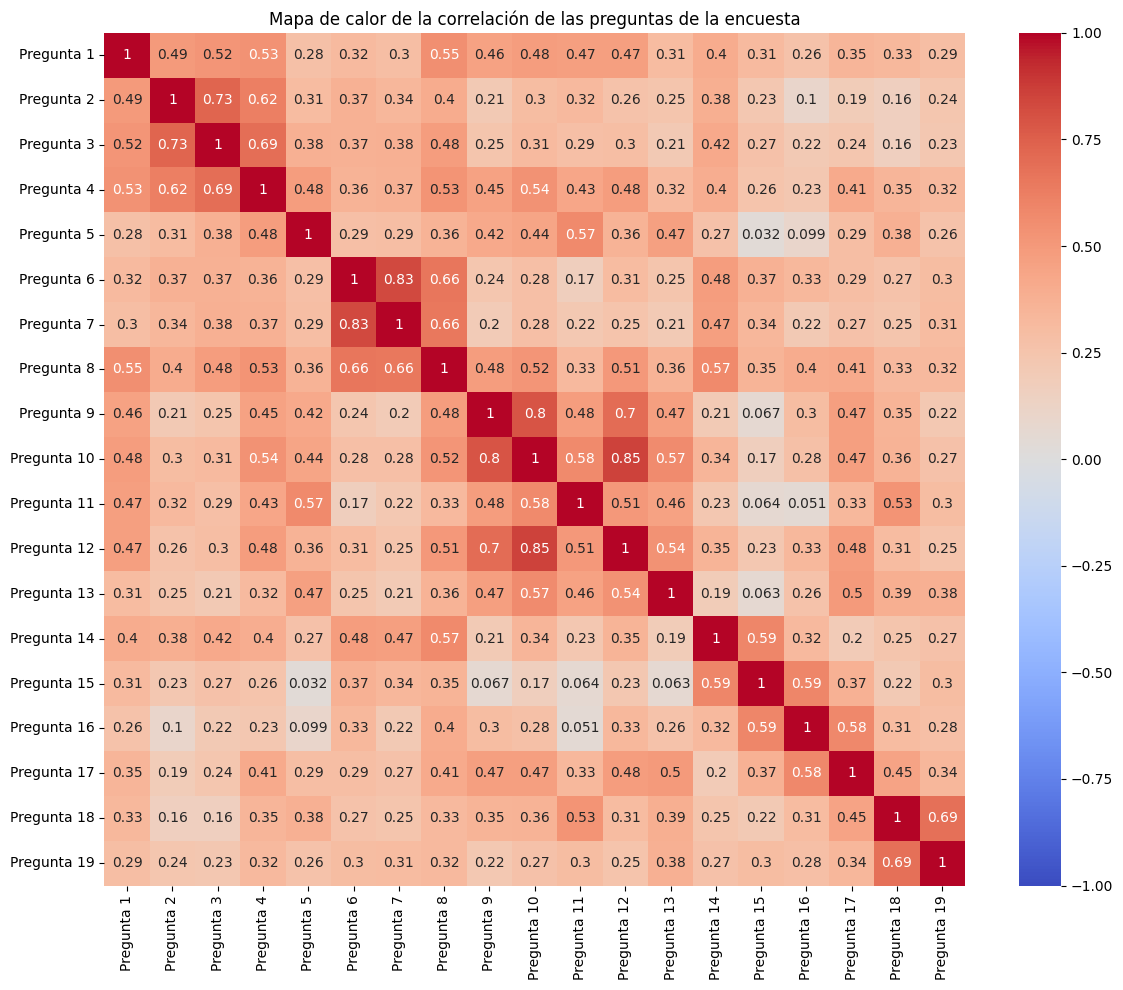

In [ ]:
# Eliminamos los espacios en blanco de los nombres de las columnas
data.columns = data.columns.str.strip()

# Ejecutamos el análisis de correlación
columnas_para_analizar = [f'Pregunta {i}' for i in range(1, 20)]

# Calculamos la matriz de correlación
Matriz_correlacion = data[columnas_para_analizar].corr()

# Creamos un mapa de calor de la matriz de correlación
plt.figure(figsize=(12, 10))
sns.heatmap(Matriz_correlacion, annot=True, cmap='coolwarm', vmin=-1, vmax=1, center=0)
plt.title('Mapa de calor de la correlación de las preguntas de la encuesta')
plt.tight_layout()
plt.show()

 Al observar la matriz de correlación presentada, se identifican varias correlaciones significativas entre las preguntas, lo que sugiere que algunas de ellas podrían estar midiendo aspectos similares o relacionados del constructo.

* **Correlaciones fuertes:**

*Pregunta 8 y Pregunta 9:* Presentan una correlación bastante alta de 0.85, lo que sugiere que las respuestas a estas preguntas están altamente relacionadas. Esto podría indicar que ambas preguntas están midiendo un aspecto muy similar del constructo, lo que podría llevar a considerar si ambas son necesarias o si alguna es redundante.

*Pregunta 10 y Pregunta 9:* Existe una correlación elevada de 0.80, lo que indica que los encuestados probablemente responden de manera similar a estas dos preguntas, lo que nuevamente puede apuntar a que miden aspectos muy cercanos.

*Pregunta 10 y Pregunta 12:* Correlación elevada de 0.84, lo que indica que estas preguntas están altamente alineadas en el constructo medido, o que los encuestados tienden a percibirlas como equivalentes.

*Pregunta 12 y Pregunta 10:* Presentan una alta correlación de 0.85, lo cual es un indicio claro de que están midiendo un aspecto muy parecido o que los encuestados tienden a percibirlas como casi equivalentes.

* **Correlaciones moderadas:**

*Pregunta 6 y Pregunta 8:* Tienen una correlación moderada de 0.66, lo que indica que hay una relación significativa entre ambas preguntas, pero no al nivel de las correlaciones más fuertes. Podrían estar midiendo aspectos relacionados, pero con diferencias importantes.

*Pregunta 4 y Pregunta 8:* Tienen una correlación de 0.66, lo que sugiere que estas preguntas están relacionadas y podrían formar parte de un mismo componente teórico del constructo. Esto será importante a tener en cuenta al momento de realizar análisis factoriales.

*Pregunta 1 y Pregunta 8:* Correlación de 0.55, lo que muestra que hay cierta relación entre las respuestas, aunque no es tan fuerte como en otros casos.

* **Correlaciones más bajas**

*Pregunta 3 y Pregunta 15:* Presentan una correlación muy baja de 0.032, lo que indica que casi no hay relación entre las respuestas a estas preguntas. Esto sugiere que miden aspectos completamente diferentes del constructo o que los encuestados no ven ninguna conexión entre ellas.

*Pregunta 12 y Pregunta 18:* Con una correlación baja de 0.051, estas preguntas muestran poca relación, lo que implica que miden aspectos distintos o no conectados en la mente de los encuestados.

* **Posible redundancia en ítems:**

*Preguntas 8, 9 y 10:* Estas tres preguntas presentan correlaciones bastante elevadas entre sí (superiores a 0.80), lo que sugiere que podría haber cierta redundancia. Podrías considerar si son necesarias todas, o si hay posibilidad de reducirlas, sobre todo si el objetivo es simplificar el cuestionario sin perder información valiosa.

* **Correlaciones bajas:**

Si bien todas las preguntas muestran correlaciones positivas, algunas presentan coeficientes muy bajos, lo que podría sugerir que no están tan relacionadas entre sí. Por ejemplo, *las Preguntas 3 y 19* tienen una correlación de 0.089, lo que sugiere una débil asociación. Este tipo de relaciones bajas podrían indicar que estas preguntas miden aspectos diferentes del constructo o simplemente no tienen una relación directa significativa.

* **Sugerencia de agrupaciones:**

*Preguntas 8, 9, 10 y 12:* Las correlaciones fuertes entre estas preguntas sugieren que pueden estar midiendo un mismo subconstructo dentro del constructo general de la encuesta. Es probable que estas preguntas se agrupen en un mismo factor en un análisis factorial.

*Preguntas 7 y 8:* También parecen estar estrechamente relacionadas y podrían formar un subgrupo coherente en el análisis factorial.

### **Análisis componentes principales (PCA)**

El PCA es una técnica estadística que se utiliza para reducir la dimensionalidad de un conjunto de datos y extraer la información más importante de los datos. El PCA identifica los componentes principales que explican la mayor parte de la varianza en los datos y los ordena en función de su importancia.

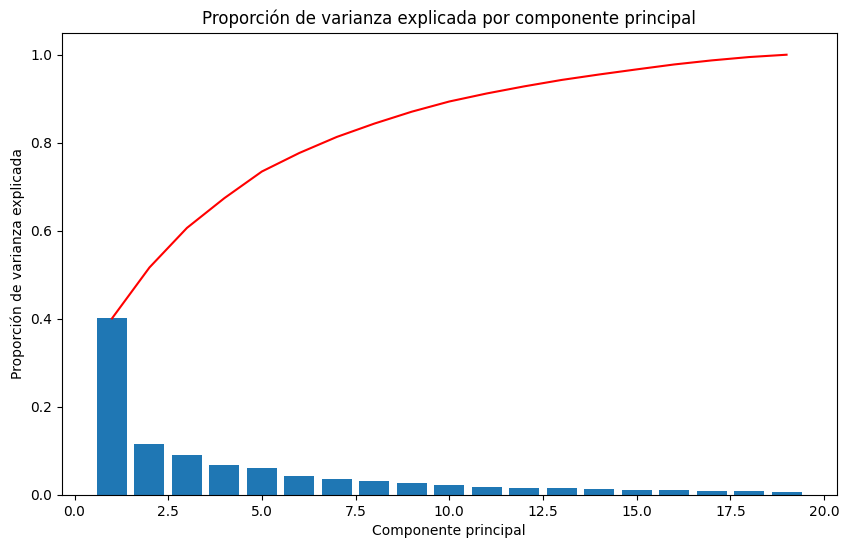

Proporción de varianza explicada para los primeros 5 componentes:
CP1: 0.4007
CP2: 0.1158
CP3: 0.0899
CP4: 0.0677
CP5: 0.0605
Proporción acumulada de varianza explicada:
CP1: 0.4007
CP2: 0.5165
CP3: 0.6064
CP4: 0.6741
CP5: 0.7346
CP6: 0.7768
Número de componentes para explicar el 80% de la varianza: 7


In [ ]:
# Realizamos el análisis de componentes principales (PCA)
scaler = StandardScaler()
scaled_data = scaler.fit_transform(data[columnas_para_analizar])

pca = PCA()
pca_result = pca.fit_transform(scaled_data)

# Calculamos la proporción de varianza explicada
explained_variance_ratio = pca.explained_variance_ratio_

# Calculamos la proporción acumulada de varianza explicada
cumulative_variance_ratio = np.cumsum(explained_variance_ratio)

# Graficamos la proporción de varianza explicada
plt.figure(figsize=(10, 6))
plt.bar(range(1, len(explained_variance_ratio) + 1), explained_variance_ratio)
plt.plot(range(1, len(cumulative_variance_ratio) + 1), cumulative_variance_ratio, 'r-')
plt.xlabel('Componente principal')
plt.ylabel('Proporción de varianza explicada')
plt.title('Proporción de varianza explicada por componente principal')
plt.show()


# Imprimimos la proporción de varianza explicada para los primeros componentes
print("Proporción de varianza explicada para los primeros 5 componentes:")
for i, ratio in enumerate(explained_variance_ratio[:5], 1):
    print(f"CP{i}: {ratio:.4f}")

# Imprimimos la proporción acumulada de varianza explicada
print("Proporción acumulada de varianza explicada:")
for i, ratio in enumerate(cumulative_variance_ratio, 1):
    if ratio > 0.8:
        print(f"Número de componentes para explicar el 80% de la varianza: {i}")
        break
    print(f"CP{i}: {ratio:.4f}")

* **Proporción de varianza explicada por cada componente:**

*CP1:* **40.07%** de la varianza total es explicada por el primer componente principal. Esto indica que este componente captura una cantidad considerable de información del dataset.

*CP2:* **11.58%** es explicada por el segundo componente, lo que sugiere que este también es relevante, pero considerablemente menos que el primero.

*CP3:* **8.99%** es explicada por el tercer componente, contribuyendo de manera significativa a la variabilidad del conjunto de datos.

*CP4: **6.77%** y CP5:* **6.05%**   indican que los siguientes componentes aportan menor información individualmente.


* **Varianza acumulada:**

Después de los primeros 5 componentes, la varianza acumulada es del **73.46%**, lo que significa que estos componentes explican casi tres cuartas partes de la varianza en el dataset.

*CP6:*  **77.68%** y *CP7:* **80%.** Para explicar el 80% de la varianza, necesitas incluir 7 componentes principales. Esta cantidad es bastante razonable, ya que significa que 7 componentes capturan la mayoría de la información relevante de tu dataset sin necesidad de incluir los 19.

* **Gráfico de codo:**

El gráfico muestra la curva de codo (elbow plot) con la línea roja que acumula la proporción de varianza explicada y las barras azules que representan la proporción explicada por cada componente.

* **Interpretación de los componentes:**

Se puede observar que el CP1 es claramente el componente más significativo, ya que tiene la mayor proporción de varianza explicada.

A partir del CP2, las barras comienzan a disminuir gradualmente. El punto de inflexión en la curva roja ocurre alrededor del CP7, que marca el número de componentes necesarios para explicar el 80% de la varianza.

* **Número de componentes para explicar el 80% de la varianza:**

Necesitamos 7 componentes para explicar el 80% de la varianza, lo que sugiere que hay varios factores subyacentes o dimensiones que están representados en los datos, aunque el primer componente sigue siendo el más fuerte.

### **Cargas de los componentes principales**

El análisis de cargas muestra que las preguntas relacionadas con las motivaciones económicas y personales, como la autonomía, los ingresos y las habilidades emprendedoras, tienen una mayor carga en CP1. Por otro lado, las preguntas que implican un enfoque en redes, tradición familiar y factores externos tienen más peso en CP2.

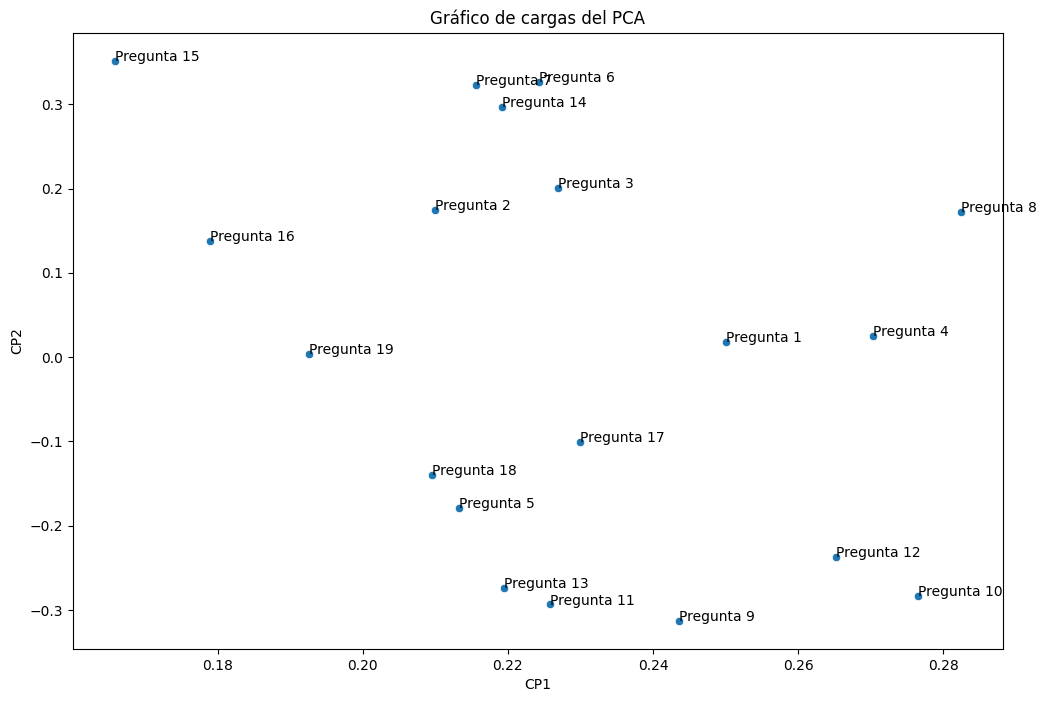

Cargas para CP1 y CP2:
                  CP1       CP2
Pregunta 1   0.250029  0.017837
Pregunta 2   0.209946  0.174658
Pregunta 3   0.226845  0.200405
Pregunta 4   0.270343  0.024747
Pregunta 5   0.213243 -0.179057
Pregunta 6   0.224323  0.326720
Pregunta 7   0.215554  0.323355
Pregunta 8   0.282411  0.172413
Pregunta 9   0.243623 -0.312559
Pregunta 10  0.276544 -0.282750
Pregunta 11  0.225849 -0.293247
Pregunta 12  0.265276 -0.236759
Pregunta 13  0.219463 -0.274047
Pregunta 14  0.219241  0.297183
Pregunta 15  0.165876  0.351582
Pregunta 16  0.179008  0.138248
Pregunta 17  0.229888 -0.100238
Pregunta 18  0.209566 -0.139337
Pregunta 19  0.192584  0.003953


In [ ]:
# Obtenemos las cargas (coeficientes) de los dos primeros componentes principales
loadings = pca.components_.T[:, :2]

# Creamos un DataFrame con las cargas
loadings_df = pd.DataFrame(loadings, columns=['CP1', 'CP2'], index=columnas_para_analizar)

# Graficamos las cargas
plt.figure(figsize=(12, 8))
sns.scatterplot(data=loadings_df, x='CP1', y='CP2')
for i, txt in enumerate(loadings_df.index):
    plt.annotate(txt, (loadings_df.iloc[i, 0], loadings_df.iloc[i, 1]))
plt.xlabel('CP1')
plt.ylabel('CP2')
plt.title('Gráfico de cargas del PCA')
plt.show()

# Imprimimos las cargas de los dos primeros componentes principales
print("Cargas para CP1 y CP2:")
print(loadings_df)

* **CP1 (Componente Principal 1)** parece estar relacionado con motivaciones más económicas y personales, como "obtener altos ingresos económicos" (Pregunta 4) o "invertir recursos financieros propios" (Pregunta 12), que tienen una alta carga positiva en este componente. Cuanto más alto el valor en CP1, mayor es el enfoque en factores económicos y financieros.

* **CP2 (Componente Principal 2)** podría estar relacionado con aspectos más técnicos o sociales, como "continuar con una tradición familiar de emprendedores" (Pregunta 13) o "contar con una red de contactos en el mercado potencial" (Pregunta 19). Preguntas con alta carga en CP2 parecen estar más enfocadas en el entorno, las redes y la tradición.

**Detalle por pregunta:**

* **Pregunta 1 (Sueño de ser emprendedor):** CP1: 0.2500, CP2: 0.0178

 Esta motivación está más fuertemente asociada con el primer componente principal, lo que sugiere que el sueño de ser emprendedor tiene un peso considerable en el grupo de factores representados por CP1. Sin embargo, no tiene una relación importante con CP2.

* **Pregunta 2 (Flexibilidad de tiempo):** CP1: 0.2099, CP2: 0.1746

 La motivación de flexibilidad en el tiempo está distribuida entre ambos componentes, pero tiene mayor peso en CP1, aunque CP2 también tiene una influencia moderada. Esto indica que esta motivación podría estar vinculada tanto con las aspiraciones generales de emprender (CP1) como con aspectos más específicos que podrían estar representados por CP2.

* **Pregunta 3 (Autonomía e independencia):** CP1: 0.2268, CP2: 0.2004

 Similar a la pregunta anterior, la autonomía e independencia tienen una asociación con ambos componentes, siendo CP1 el más fuerte. Esto sugiere que es un motivo generalizado en las características principales del emprendedor.

* **Pregunta 4 (Altos ingresos económicos):** CP1: 0.2703, CP2: 0.0247

 Esta motivación está fuertemente asociada con CP1, lo que indica que los altos ingresos son un factor que juega un papel importante en el conjunto de factores representados por CP1, pero no en CP2.

* **Pregunta 5 (Construir negocio familiar):** CP1: 0.2132, CP2: -0.1790

 Aunque tiene una carga positiva en CP1, la carga negativa en CP2 podría indicar que la motivación para construir un negocio familiar está relacionada con otros factores menos representados por CP2.

* **Pregunta 6 (Explotar conocimiento):** CP1: 0.2243, CP2: 0.3267

 Esta es una de las pocas preguntas con una carga importante tanto en CP1 como en CP2, con una mayor carga en CP2. Esto sugiere que el deseo de explotar el conocimiento tiene una conexión significativa con el conjunto de factores que representa CP2..

* **Pregunta 7 (Aplicar experiencia adquirida):** CP1: 0.2155, CP2: 0.3233

 Similar a la pregunta 6, la motivación para aplicar experiencia está relacionada con ambos componentes, pero es más fuerte en CP2. Puede ser un factor específico dentro del grupo de motivaciones prácticas.

* **Pregunta 8 (Poner en práctica habilidades):** CP1: 0.2824, CP2: 0.1724

 Esta motivación está principalmente asociada con CP1, pero también tiene algo de peso en CP2. El deseo de aplicar habilidades parece ser un factor clave en las motivaciones generales de emprender.

* **Pregunta 9 (Financiación externa):** CP1: 0.2436, CP2: -0.3125

 Aunque tiene un peso considerable en CP1, la carga negativa en CP2 sugiere que la motivación para aprovechar la financiación externa puede estar en desacuerdo con los factores representados por CP2.

* **Pregunta 10 (Políticas públicas):** CP1: 0.2765, CP2: -0.2827

 Al igual que la pregunta 9, esta motivación está fuertemente asociada con CP1, pero con una carga negativa en CP2, lo que sugiere una posible divergencia con los factores representados por CP2.

* **Pregunta 11 (Acceso a apoyos públicos):** CP1: 0.2258, CP2: -0.2932

 Similar a las dos preguntas anteriores, esta motivación está más relacionada con CP1, pero la carga negativa en CP2 indica que no está alineada con los factores de ese componente.

* **Pregunta 12 (Recursos financieros propios):** CP1: 0.2653, CP2: -0.2368

 Esta motivación es más fuerte en CP1 y tiene una relación negativa en CP2, lo que sugiere que la inversión de recursos propios no es tan relevante en los factores de CP2.

* **Pregunta 13 (Tradición familiar):** CP1: 0.2195, CP2: -0.2740

 Similar a la pregunta 12, está más relacionada con CP1, pero tiene una asociación negativa con CP2, lo que podría indicar que continuar una tradición familiar no encaja con los factores representados por CP2.

* **Pregunta 14 (Contribuir al bienestar de la comunidad):** CP1: 0.2192, CP2: 0.2972
 Esta motivación está más equilibrada entre ambos componentes, pero tiene una mayor asociación con CP2. Esto sugiere que el bienestar de la comunidad podría estar más relacionado con factores específicos que representa CP2.

* **Pregunta 15 (Detectar una necesidad insatisfecha):** CP1: 0.1659, CP2: 0.3516

 La motivación para atender una necesidad insatisfecha está más fuertemente asociada con CP2, lo que indica que está relacionada con factores específicos o prácticos más que con motivaciones generales de emprender.

* **Pregunta 16 (Desarrollo de nuevo producto/servicio):** CP1: 0.1790, CP2: 0.1382

 Esta motivación está más distribuida entre ambos componentes, aunque no tiene una carga muy fuerte en ninguno. Esto indica que el desarrollo de un nuevo producto o servicio tiene una relación moderada con los factores generales.

* **Pregunta 17 (Nuevo método de producción):** CP1: 0.2299, CP2: -0.1002

 Esta motivación está más asociada con CP1, pero con una carga negativa en CP2, lo que indica que el desarrollo de un nuevo método de producción podría no estar alineado con los factores representados por CP2.

* **Pregunta 18 (Nuevo método de producción):** CP1: 0.2096, CP2: -0.1393

 Similar a la pregunta 17, con una mayor carga en CP1 y una relación negativa con CP2.

* **Pregunta 19 (Red de contactos):** CP1: 0.1926, CP2: 0.0039

 La red de contactos tiene una pequeña relación con ambos componentes, pero ninguna es especialmente fuerte.



 En general, las motivaciones que tienen más relación con CP1 suelen estar relacionadas con factores generales del emprendimiento, como el sueño de emprender, los ingresos económicos, y la puesta en práctica de habilidades. Mientras que las motivaciones más asociadas a CP2 tienden a estar relacionadas con factores más específicos o contextuales, como la explotación del conocimiento, la experiencia y el bienestar de la comunidad.

### **rotacion ortogonal varimax**

La rotación ortogonal varimax es una técnica que se utiliza para rotar los componentes principales de manera que sean más interpretables y fáciles de entender. La rotación varimax busca maximizar la varianza explicada por cada componente y minimizar la correlación entre los componentes.

Eigenvalues:
[7.61323787 2.19983058 1.70825143 1.28691789 1.14913528 0.80129788
 0.69228682 0.57482544 0.51477722 0.439462   0.34700429 0.30694594
 0.27743872 0.2355525  0.21987854 0.21255807 0.17523729 0.14486505
 0.1004972 ]


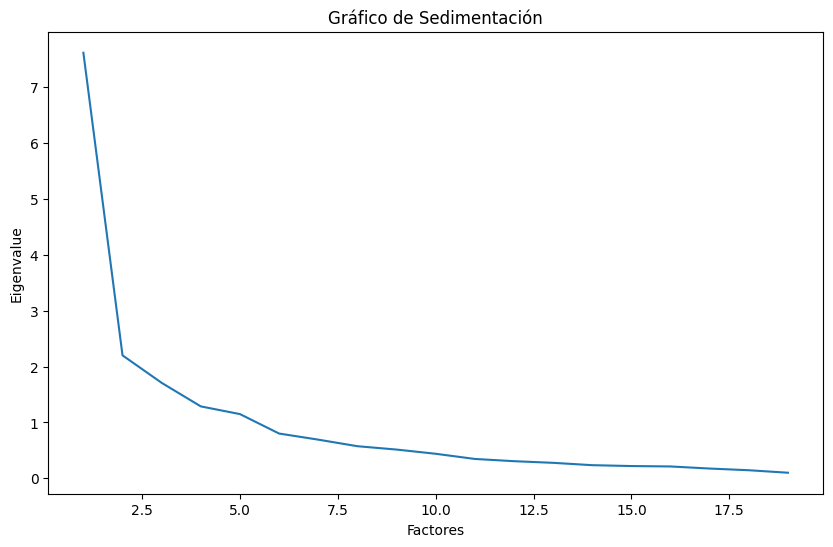

Cargas factoriales después de la rotación varimax:
              Factor1   Factor2   Factor3   Factor4   Factor5
Pregunta 1   0.384116  0.594829  0.225899  0.129126  0.124384
Pregunta 2   0.074351  0.850880  0.012639  0.092443  0.183192
Pregunta 3   0.106391  0.858995  0.099728  0.052306  0.211970
Pregunta 4   0.365611  0.725452  0.096681  0.189177  0.169609
Pregunta 5   0.436213  0.312058 -0.250620  0.418956  0.225858
Pregunta 6   0.121775  0.161232  0.160410  0.127038  0.880920
Pregunta 7   0.090189  0.172186  0.067776  0.150414  0.900412
Pregunta 8   0.402581  0.324042  0.243680  0.081363  0.653198
Pregunta 9   0.856112  0.136841  0.096827  0.076999  0.083281
Pregunta 10  0.876676  0.217056  0.108418  0.097343  0.149725
Pregunta 11  0.556490  0.314321 -0.184335  0.474898  0.041184
Pregunta 12  0.838929  0.182885  0.206768  0.035644  0.153553
Pregunta 13  0.622087  0.062141  0.037899  0.399561  0.109879
Pregunta 14  0.104745  0.397588  0.374269  0.061113  0.503404
Pregunta 15 -0.0594

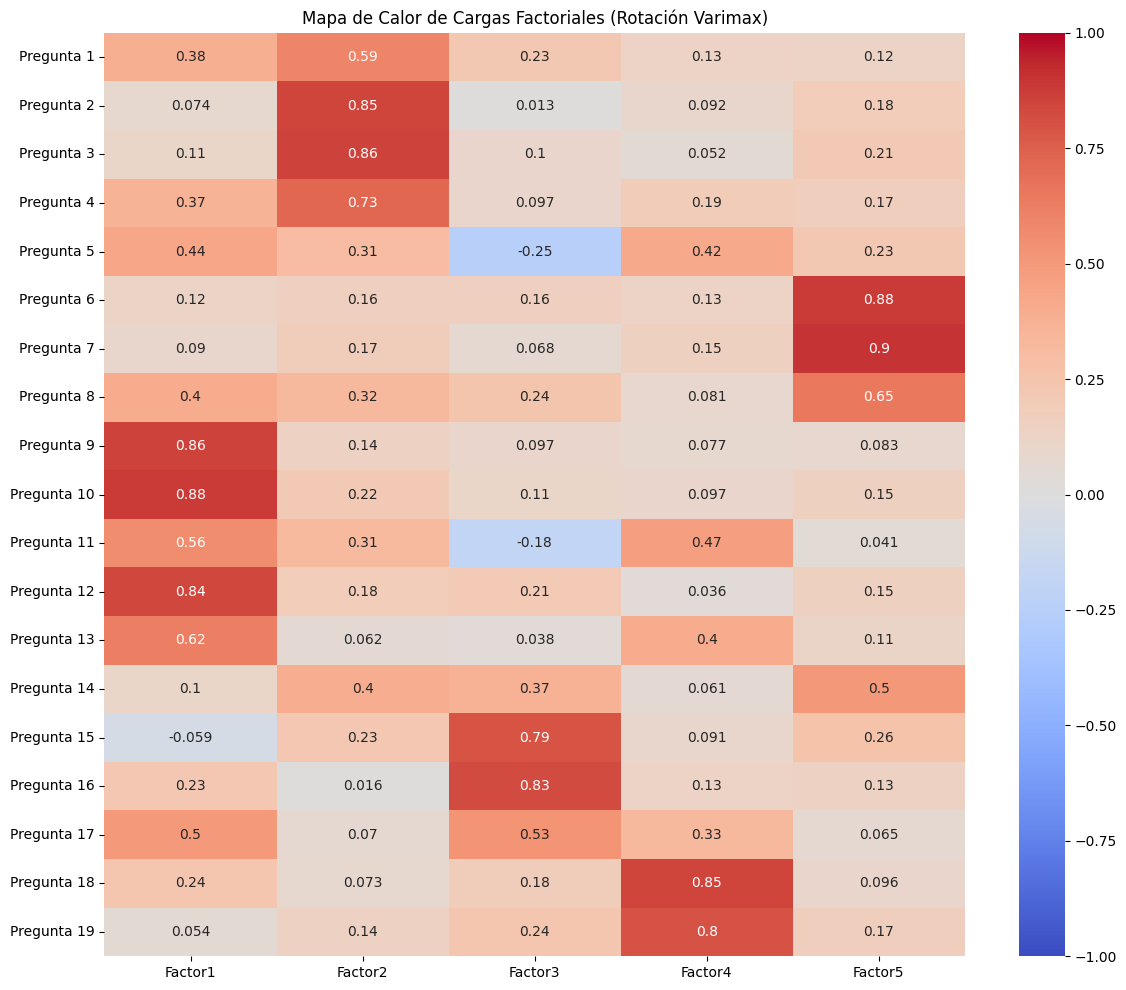

In [ ]:
# Seleccionamos las columnas de las 19 preguntas (asegurándonos de que sean los datos)
preguntas = [col for col in data.columns if col.startswith('Pregunta')]
datos_preguntas = data[preguntas]

# Eliminamos las filas con valores faltantes
datos_preguntas = datos_preguntas.dropna()

# Realizamos el análisis factorial (asegurarse de pasar los datos numéricos, no los nombres de las columnas)
fa = FactorAnalyzer(rotation=None, n_factors=5, method='principal')
fa.fit(datos_preguntas)  # Pasar los datos de las preguntas, no los nombres de las columnas

# Obtenemos los eigenvalues y la varianza explicada
ev, v = fa.get_eigenvalues()
print("Eigenvalues:")
print(ev)

# Creamos un gráfico de sedimentación
plt.figure(figsize=(10, 6))
plt.plot(range(1, len(ev) + 1), ev)  # Asegurarse de que el rango coincida con el número de factores
plt.title('Gráfico de Sedimentación')
plt.xlabel('Factores')
plt.ylabel('Eigenvalue')
plt.show()

# Realizamos la rotación varimax
fa_varimax = FactorAnalyzer(rotation='varimax', n_factors=5, method='principal')
fa_varimax.fit(datos_preguntas)  # Usar los datos numéricos, no los nombres de las columnas

# Obtenemos las cargas factoriales
loadings = pd.DataFrame(fa_varimax.loadings_, columns=[f'Factor{i+1}' for i in range(5)], index=preguntas)

# Mostramos las cargas factoriales
print("Cargas factoriales después de la rotación varimax:")
print(loadings)

# Creamos un mapa de calor de las cargas factoriales
plt.figure(figsize=(12, 10))
sns.heatmap(loadings, annot=True, cmap='coolwarm', vmin=-1, vmax=1, center=0)
plt.title('Mapa de Calor de Cargas Factoriales (Rotación Varimax)')
plt.tight_layout()
plt.show()


1. **Eigenvalores:**

Los eigenvalores nos indican cuánta varianza del total explica cada factor. Basándonos en nuestro análisis, los cinco primeros factores tienen eigenvalores mayores a 1, lo que los convierte en los más relevantes para explicar la motivación emprendedora. En nuestro caso, los eigenvalores de los cinco primeros factores son:

*Factor 1:*   7.61

*Factor 2:*   2.20

*Factor 3:*   1.71

*Factor 4:*   1.29

*Factor 5:*   1.15

Estos cinco factores explican una porción significativa de la varianza en tus datos, siendo el Factor 1 el que explica la mayor cantidad. Los eigenvalores restantes son mucho menores, indicando que los factores a partir del sexto en adelante explican menos varianza y, por lo tanto, tienen menor importancia.

2. **Cargas factoriales:**

Las cargas factoriales después de la rotación varimax muestran qué tanto se asocian las preguntas con cada factor. Los valores más altos indican una mayor asociación con el factor correspondiente.

* **Factor 1:** Está fuertemente cargado en las preguntas relacionadas con la posibilidad de acceder a apoyos públicos y financiación, como las preguntas 9, 10 y 12. Además, también incluye la motivación de "invertir recursos propios" (Pregunta 11). Esto sugiere que este factor refleja una orientación hacia el manejo de recursos y financiamiento.

* **Factor 2:** Las preguntas 1, 2, 3 y 4, que representan motivaciones como el "sueño de ser emprendedor", "flexibilidad" e "independencia en el trabajo", están altamente cargadas en este factor. Parece estar relacionado con la búsqueda de libertad personal y autonomía, elementos clave en muchas motivaciones emprendedoras.

* **Factor 3:** En este caso, las preguntas 15, 16 y 17, relacionadas con la innovación, como "desarrollar un nuevo producto o servicio" y "detectar necesidades insatisfechas", tienen las cargas más altas. Este factor claramente agrupa a aquellos motivados por la innovación y la creación de valor nuevo.

* **Factor 4:** Las preguntas 18 y 19, vinculadas con la tradición familiar y la continuidad del negocio familiar, están fuertemente asociadas a este factor. Representa a los emprendedores que buscan continuar un legado familiar o construir sobre la tradición.

* **Factor 5:** Este factor está relacionado principalmente con la explotación del conocimiento y la experiencia previa, como se ve en las preguntas 6 y 7. Las cargas altas indican que está vinculado con la puesta en práctica de habilidades adquiridas y el aprovechamiento de conocimientos previos en el ámbito emprendedor.

**Interpretación:**

**El Factor 1** destaca el papel de los recursos financieros y el acceso a apoyos públicos, elementos clave para quienes buscan estabilidad económica o apoyo externo para emprender.

**El Factor 2** está orientado hacia el ideal de independencia, libertad y autonomía personal, factores motivadores comunes en emprendedores que buscan más control sobre su tiempo y sus proyectos.

**El Factor 3** enfatiza la importancia de la innovación, capturando a quienes se sienten motivados por crear algo nuevo o resolver problemas no atendidos.

**El Factor 4** refleja el deseo de continuar con un negocio familiar o tradición, vinculando el emprendimiento con el legado y la herencia.

**El Factor 5:**   pone de manifiesto la importancia del conocimiento adquirido y la experiencia previa en el desarrollo emprendedor.

Esto sugiere que las personas en tu muestra se agrupan según motivaciones diversas como independencia, legado familiar, innovación y recursos financieros, lo que te puede ayudar a interpretar y entender mejor los patrones en las motivaciones para emprender.

### **Interpretación general de los valores obtenidos**

1. **Interpretación de los factores:**

**Identificación de grupos motivacionales:** Los factores obtenidos reflejan diferentes agrupaciones de motivaciones emprendedoras. Cada factor representa un conjunto de preguntas que están correlacionadas entre sí, lo que sugiere que las personas que responden de manera similar a estas preguntas probablemente comparten motivaciones similares.

* **Factor 1:** Las personas motivadas por este factor probablemente estén enfocadas en encontrar maneras de asegurar financiación externa o aprovechar apoyos públicos. Este grupo se preocupa por los recursos financieros como elemento clave para su éxito emprendedor.

* **Factor 2:** Este factor agrupa a aquellos individuos que buscan emprender para tener más control sobre su tiempo y trabajo, persiguiendo flexibilidad y autonomía en su vida laboral. Son emprendedores que valoran la libertad personal por encima de otras consideraciones.

* **Factor 3:** Aquí están las personas que están motivadas por la creación de productos, servicios o métodos nuevos. Estos emprendedores tienen una orientación hacia la innovación y el desarrollo de soluciones a problemas insatisfechos en el mercado.

* **Factor 4:** Este grupo de emprendedores está motivado por el deseo de continuar con un negocio familiar o construir un legado. Para ellos, la tradición y los valores familiares son fundamentales en sus decisiones empresariales.

* **Factor 5:** Los individuos motivados por este factor buscan explotar el conocimiento y la experiencia que han adquirido a lo largo de su vida profesional. Quieren aplicar lo que saben para crear un negocio exitoso.

2. **Clustering y segmentación:**

Basado en los resultados de los clusters y el análisis factorial, es posible segmentar a los emprendedores en grupos con características comunes en sus motivaciones:

* **Cluster 0:** Este grupo muestra motivaciones altas en todos los factores. Esto indica que son personas que tienen un perfil altamente completo y equilibrado en términos de sus motivaciones. Podrían estar impulsados por una combinación de autonomía, recursos financieros, innovación y tradición familiar.

* **Cluster 1:** Este grupo tiene puntuaciones más bajas en todos los factores, lo que sugiere que sus motivaciones para emprender son más limitadas o menos intensas en comparación con otros grupos. Podrían estar menos motivados o ser más cautelosos en su emprendimiento.

* **Cluster 2:** Este grupo tiene altos niveles en los factores clave, lo que lo hace similar al Cluster 0, pero con diferencias que podrían deberse a una mayor inclinación hacia ciertos aspectos como la financiación o la innovación. Este podría ser un grupo más enfocado en obtener apoyos y utilizar recursos externos para sus proyectos.

* **Cluster 3:** Tiene motivaciones intermedias, mostrando un interés en la independencia y la tradición familiar, pero menos impulsados por la innovación o los recursos financieros.

* **Cluster 4:** Este grupo tiene un perfil muy balanceado, mostrando que sus principales motivaciones incluyen tanto la autonomía como la tradición y los recursos financieros.

## **Análisis Factorial Confirmatorio**

### **Análisis de Ecuaciones Estructurales (SEM)**

In [ ]:
# Elimina los espacios en los nombres de las columnas del DataFrame
data_preguntas.columns = data_preguntas.columns.str.replace(' ', '')

# Verifica que los nombres de las columnas no tengan espacios
print(data_preguntas.columns)


Index(['Pregunta1', 'Pregunta2', 'Pregunta3', 'Pregunta4', 'Pregunta5',
       'Pregunta6', 'Pregunta7', 'Pregunta8', 'Pregunta9', 'Pregunta10',
       'Pregunta11', 'Pregunta12', 'Pregunta13', 'Pregunta14', 'Pregunta15',
       'Pregunta16', 'Pregunta17', 'Pregunta18', 'Pregunta19'],
      dtype='object')


In [ ]:
# Definir el modelo SEM con los factores y preguntas
model_desc = """
# Definición de factores latentes y las preguntas asociadas
Factor1 =~ Pregunta9 + Pregunta10
Factor2 =~ Pregunta2 + Pregunta3
Factor3 =~ Pregunta15 + Pregunta16
Factor4 =~ Pregunta18 + Pregunta19
Factor5 =~ Pregunta6 + Pregunta7

# Relación entre factores
Factor2 ~ Factor1
Factor3 ~ Factor1
Factor4 ~ Factor3
Factor5 ~ Factor3
Factor5 ~ Factor1
Factor2 ~~ Factor5
"""

# Cargar el modelo
model = Model(model_desc)
model.load_dataset(data_preguntas)

# Ajustar el modelo a los datos
optimizer = Optimizer(model)
result = model.fit()

# Mostrar los resultados del ajuste del modelo
print(result)

Name of objective: MLW
Optimization method: SLSQP
Optimization successful.
Optimization terminated successfully
Objective value: 0.410
Number of iterations: 39
Params: 1.376 0.882 1.316 1.019 0.819 0.326 0.279 0.682 0.438 0.166 0.230 0.641 0.934 0.493 0.845 0.620 0.090 0.515 0.584 0.575 0.461 0.273 0.210 0.064 0.191 0.467


**Valor del objetivo:** 0.410

Este es el valor de la función objetivo al final de la optimización. Un valor bajo generalmente nos indica un buen ajuste del modelo por lo que nuestro valor representa un buen ajuste.

In [ ]:
# Métricas de desempeño
resultados = calc_stats(model)

# Acceder directamente a las métricas que buscas: CFI, TLI y RMSEA
cfi = resultados.get('CFI', None)
tli = resultados.get('TLI', None)
rmsea = resultados.get('RMSEA', None)

# Verificar si se calcularon correctamente
if cfi is not None and tli is not None and rmsea is not None:
    print(f"CFI: {cfi}")
    print(f"TLI: {tli}")
    print(f"RMSEA: {rmsea}")
else:
    print("No se encontraron algunas de las métricas CFI, TLI o RMSEA.")

CFI: Value    0.963001
Name: CFI, dtype: float64
TLI: Value    0.942587
Name: TLI, dtype: float64
RMSEA: Value    0.077728
Name: RMSEA, dtype: float64


1. **CFI (Comparative Fit Index) = 0.963**

El modelo está ajustándose de manera excelente en comparación con el modelo nulo.

2. **TLI (Tucker-Lewis Index) = 0.943**

El modelo tiene una buena relación entre el ajuste y la complejidad.

3. **RMSEA (Root Mean Square Error of Approximation) = 0.078**

El modelo tiene un ajuste aceptable según el RMSEA, lo que sugiere que se ajusta razonablemente bien a los datos, con margen para mejoras si se desea optimizarlo aún más.

## **Análisis predictivo: clustering sólo a los factores**

### **Kmeans**

In [ ]:
# Filtrar nuestro dataset original para que solo contenga las 19 preguntas correspondientes
preguntas_utilizadas = ['Pregunta 1', 'Pregunta 2', 'Pregunta 3', 'Pregunta 4','Pregunta 5','Pregunta 6','Pregunta 7','Pregunta 8','Pregunta 9','Pregunta 10','Pregunta 11','Pregunta 12','Pregunta 13','Pregunta 14','Pregunta 15','Pregunta 16','Pregunta 17','Pregunta 18','Pregunta 19']  # Reemplaza con los nombres correctos
data_filtrada = data[preguntas_utilizadas]

# Ahora realiza la multiplicación de matrices
puntuaciones_factores = np.dot(data_filtrada, loadings)

# Convertir las puntuaciones en un DataFrame para trabajar más fácilmente
puntuaciones_factores_df = pd.DataFrame(puntuaciones_factores, columns=['Factor1', 'Factor2', 'Factor3', 'Factor4', 'Factor5'])

In [ ]:
# Crear una instancia del escalador
scaler = StandardScaler()

# Ajustar y transformar las puntuaciones factoriales (normalización)
puntuaciones_factores_estandarizadas = scaler.fit_transform(puntuaciones_factores_df)

# Verificar las nuevas puntuaciones estandarizadas
print(puntuaciones_factores_estandarizadas[:5])  # Muestra las primeras 5 filas estandarizadas


[[-0.35027884 -0.35614089  1.2192198   0.62413752  0.41939509]
 [-0.08797857 -0.53769445 -0.15979312 -0.14528058 -0.14253498]
 [-0.32065472 -0.73242619 -1.05193448  0.02064485 -0.3096631 ]
 [ 0.64897697  0.09905062  0.02735932  0.05091582  0.05187329]
 [ 0.22869424  0.39267722 -0.33817684  0.90045584  0.50408752]]


In [ ]:
# Definir el número de clusters (K=5)
kmeans = KMeans(n_clusters=5, random_state=42)

# Ajustar el modelo a las puntuaciones estandarizadas
kmeans.fit(puntuaciones_factores_estandarizadas)

# Añadir las etiquetas de los clusters a los datos originales
puntuaciones_factores_df['Cluster'] = kmeans.labels_

# Verificar los resultados
print(puntuaciones_factores_df.head())

     Factor1    Factor2    Factor3    Factor4    Factor5  Cluster
0  23.087908  22.770898  18.606784  18.903049  22.864214        4
1  24.658123  22.025029  14.339534  15.992114  20.882509        1
2  23.265247  21.225021  11.578871  16.619859  20.293115        1
3  29.069780  24.640943  14.918663  16.734383  21.568110        4
4  26.553830  25.847237  13.787540  19.948443  23.162890        4


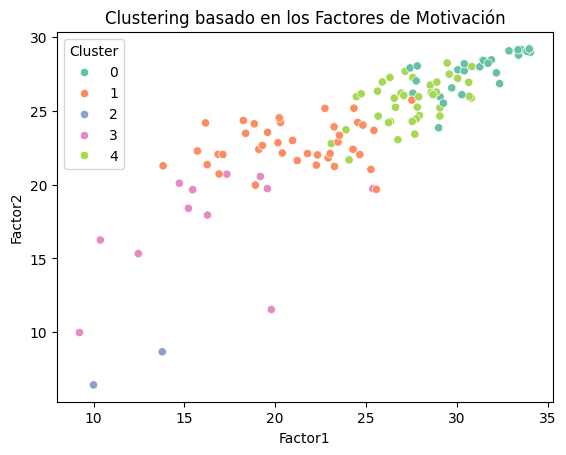

In [ ]:
# Visualización con seaborn
sns.scatterplot(x='Factor1', y='Factor2', hue='Cluster', data=puntuaciones_factores_df, palette='Set2')

plt.title('Clustering basado en los Factores de Motivación')
plt.show()

**Etiquetas del cluster:**

* *Cluster 0:* "Motivados por el equilibrio entre independencia y recursos financieros"

* *Cluster 1:* "Motivados por la menor intensidad en sus aspiraciones emprendedoras"

* *Cluster 2:* "Motivados por la financiación externa y la innovación"

* *Cluster 3:* "Motivados por la autonomía y la continuidad familiar"

* *Cluster 4:* "Motivados por la combinación de tradición, innovación y recursos financieros"

In [ ]:
# Calcular el Silhouette Score
score = silhouette_score(puntuaciones_factores_df.drop('Cluster', axis=1), kmeans.labels_)
print("Silhouette Score: ", score)

Silhouette Score:  0.30319260836968764


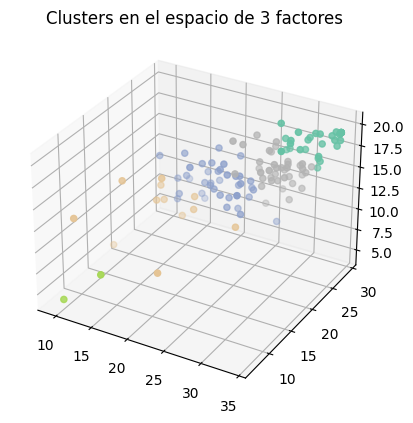

In [ ]:
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

ax.scatter(puntuaciones_factores_df['Factor1'], puntuaciones_factores_df['Factor2'], puntuaciones_factores_df['Factor3'], c=puntuaciones_factores_df['Cluster'], cmap='Set2')
plt.title('Clusters en el espacio de 3 factores')
plt.show()

### **DBSCAN (Density-Based Spatial Clustering of Applications with Noise)**

In [ ]:
# Aplicar el algoritmo DBSCAN
dbscan = DBSCAN(eps=0.5, min_samples=5)

# Ajustar el modelo a las puntuaciones estandarizadas
dbscan.fit(puntuaciones_factores_estandarizadas)

# Añadir las etiquetas de los clusters al DataFrame original
puntuaciones_factores_df['Cluster_DBSCAN'] = dbscan.labels_

# Verificar los resultados
print(puntuaciones_factores_df.head())

     Factor1    Factor2    Factor3    Factor4    Factor5  Cluster  \
0  23.087908  22.770898  18.606784  18.903049  22.864214        4   
1  24.658123  22.025029  14.339534  15.992114  20.882509        1   
2  23.265247  21.225021  11.578871  16.619859  20.293115        1   
3  29.069780  24.640943  14.918663  16.734383  21.568110        4   
4  26.553830  25.847237  13.787540  19.948443  23.162890        4   

   Cluster_DBSCAN  
0              -1  
1              -1  
2              -1  
3              -1  
4              -1  


In [ ]:
# Contar cuántos puntos han sido asignados a cada cluster
print(puntuaciones_factores_df['Cluster_DBSCAN'].value_counts())

# Ver cuántos puntos han sido marcados como ruido
n_ruido = np.sum(puntuaciones_factores_df['Cluster_DBSCAN'] == -1)
print(f"Número de puntos de ruido: {n_ruido}")

Cluster_DBSCAN
-1    94
 0    12
 1    11
 2     6
Name: count, dtype: int64
Número de puntos de ruido: 94


In [ ]:
# Filtrar los puntos que no son ruido (diferentes de -1)
puntos_validos = puntuaciones_factores_estandarizadas[puntuaciones_factores_df['Cluster_DBSCAN'] != -1]
etiquetas_validas = puntuaciones_factores_df['Cluster_DBSCAN'][puntuaciones_factores_df['Cluster_DBSCAN'] != -1]

# Calcular el Silhouette Score solo con los puntos válidos
score_dbscan = silhouette_score(puntos_validos, etiquetas_validas)
print("Silhouette Score con DBSCAN (sin ruido): ", score_dbscan)

Silhouette Score con DBSCAN (sin ruido):  0.5854886021701813


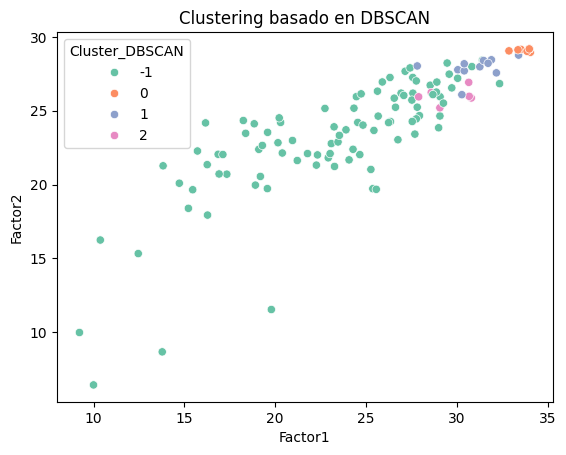

In [ ]:
# Visualización de los clusters identificados por DBSCAN
sns.scatterplot(x=puntuaciones_factores_df['Factor1'], y=puntuaciones_factores_df['Factor2'], hue=puntuaciones_factores_df['Cluster_DBSCAN'], palette='Set2')
plt.title('Clustering basado en DBSCAN')
plt.show()

In [ ]:
# Agrupar por el cluster DBSCAN para ver las características promedio
grupo_clusters_dbscan = puntuaciones_factores_df[puntuaciones_factores_df['Cluster_DBSCAN'] != -1].groupby('Cluster_DBSCAN').mean()
print(grupo_clusters_dbscan)

                  Factor1    Factor2    Factor3    Factor4    Factor5  Cluster
Cluster_DBSCAN                                                                
0               33.802396  29.128488  19.044350  22.792704  25.429238      0.0
1               30.993062  27.917723  17.724721  19.408499  24.541651      0.0
2               29.615448  26.018942  15.675721  19.365356  21.832393      4.0


### **Clustering Jerárquico**

In [ ]:
# Aplicar el clustering jerárquico
clustering_jerarquico = AgglomerativeClustering(n_clusters=5)  # Puedes cambiar el número de clusters si lo deseas

# Ajustar el modelo a las puntuaciones estandarizadas
clustering_jerarquico.fit(puntuaciones_factores_estandarizadas)

# Añadir las etiquetas de los clusters al DataFrame original
puntuaciones_factores_df['Cluster_Jerarquico'] = clustering_jerarquico.labels_

# Verificar los resultados
print(puntuaciones_factores_df.head())

     Factor1    Factor2    Factor3    Factor4    Factor5  Cluster  \
0  23.087908  22.770898  18.606784  18.903049  22.864214        4   
1  24.658123  22.025029  14.339534  15.992114  20.882509        1   
2  23.265247  21.225021  11.578871  16.619859  20.293115        1   
3  29.069780  24.640943  14.918663  16.734383  21.568110        4   
4  26.553830  25.847237  13.787540  19.948443  23.162890        4   

   Cluster_DBSCAN  Cluster_Jerarquico  
0              -1                   0  
1              -1                   2  
2              -1                   2  
3              -1                   0  
4              -1                   0  


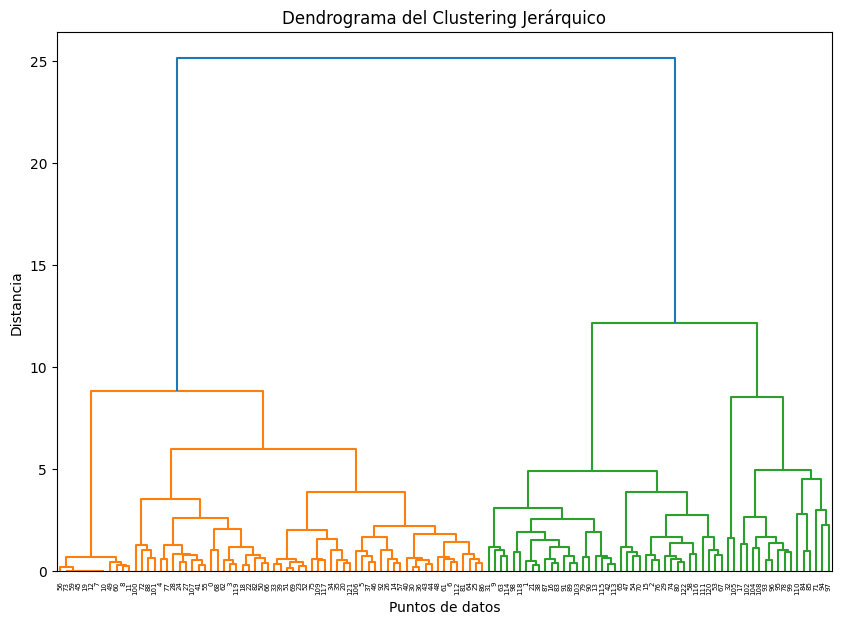

In [ ]:
from scipy.cluster.hierarchy import dendrogram, linkage

# Crear la matriz de enlaces para el dendrograma
matriz_enlaces = linkage(puntuaciones_factores_estandarizadas, method='ward')

# Graficar el dendrograma
plt.figure(figsize=(10, 7))
dendrogram(matriz_enlaces)
plt.title('Dendrograma del Clustering Jerárquico')
plt.xlabel('Puntos de datos')
plt.ylabel('Distancia')
plt.show()

In [ ]:
# Agrupar por el cluster jerárquico para ver las características promedio
grupo_clusters_jerarquico = puntuaciones_factores_df.groupby('Cluster_Jerarquico').mean()
print(grupo_clusters_jerarquico)

                      Factor1    Factor2    Factor3    Factor4    Factor5  \
Cluster_Jerarquico                                                          
0                   28.412277  26.159403  16.292068  18.283457  23.195967   
1                   15.779329  18.586011  11.290762  12.170656  16.474132   
2                   22.119857  22.958366  13.233198  14.241617  20.152732   
3                   33.802396  29.128488  19.044350  22.792704  25.429238   
4                   11.884283   7.553829   5.735648   6.754167   6.667765   

                     Cluster  Cluster_DBSCAN  
Cluster_Jerarquico                            
0                   2.517857       -0.285714  
1                   2.466667       -1.000000  
2                   1.289474       -1.000000  
3                   0.000000        0.000000  
4                   2.000000       -1.000000  


In [ ]:
# Calcular el Silhouette Score
score_jerarquico = silhouette_score(puntuaciones_factores_estandarizadas, clustering_jerarquico.labels_)
print("Silhouette Score con Clustering Jerárquico: ", score_jerarquico)

Silhouette Score con Clustering Jerárquico:  0.30369844986736044


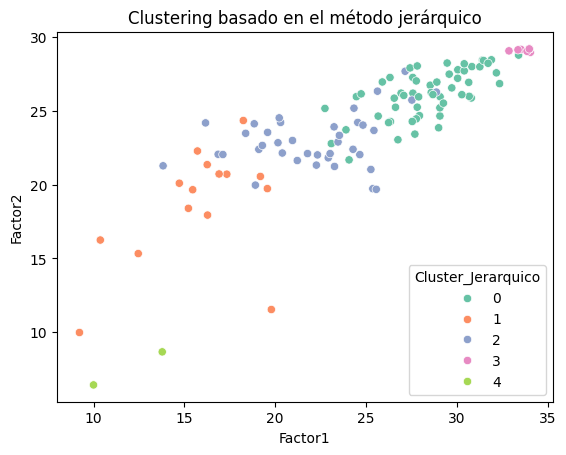

In [ ]:
# Visualización de los clusters obtenidos con clustering jerárquico
sns.scatterplot(x=puntuaciones_factores_df['Factor1'], y=puntuaciones_factores_df['Factor2'], hue=puntuaciones_factores_df['Cluster_Jerarquico'], palette='Set2')
plt.title('Clustering basado en el método jerárquico')
plt.show()

## **Análisis predictivo: potencial emprendedor**

In [ ]:
factores = puntuaciones_factores_df[['Factor1', 'Factor2', 'Factor3', 'Factor4', 'Factor5']]
factores

,Factor1,Factor2,Factor3,Factor4,Factor5
0,23.087908,22.770898,18.606784,18.903049,22.864214
1,24.658123,22.025029,14.339534,15.992114,20.882509
2,23.265247,21.225021,11.578871,16.619859,20.293115
3,29.069780,24.640943,14.918663,16.734383,21.568110
4,26.553830,25.847237,13.787540,19.948443,23.162890
...,...,...,...,...,...
118,18.906522,19.960660,15.810815,13.991151,20.828237
119,27.545680,24.269208,14.374577,17.021110,21.786730
120,25.564626,19.675450,14.222289,14.426879,17.954930
121,27.767408,27.013453,18.160895,17.682052,24.418973


In [ ]:
factores.describe()

,Factor1,Factor2,Factor3,Factor4,Factor5
count,123.000000,123.000000,123.000000,123.000000,123.000000
mean,25.184791,24.234017,14.834002,16.541753,21.385174
std,6.010811,4.125062,3.107079,3.798768,3.541027
min,9.217260,6.434915,4.312316,5.194873,5.610559
25%,20.669711,22.114681,12.752445,13.990037,20.077412
50%,26.319974,24.640943,15.048276,16.792883,21.808228
75%,29.524551,27.103116,17.132407,19.136064,23.997186
max,34.050444,29.179962,20.214952,22.926623,25.570601


In [ ]:
factores['Suma_Filas'] = factores.sum(axis=1)
factores

<ipython-input-63-417986d86e14>:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  factores['Suma_Filas'] = factores.sum(axis=1)


,Factor1,Factor2,Factor3,Factor4,Factor5,Suma_Filas
0,23.087908,22.770898,18.606784,18.903049,22.864214,106.232853
1,24.658123,22.025029,14.339534,15.992114,20.882509,97.897310
2,23.265247,21.225021,11.578871,16.619859,20.293115,92.982113
3,29.069780,24.640943,14.918663,16.734383,21.568110,106.931879
4,26.553830,25.847237,13.787540,19.948443,23.162890,109.299940
...,...,...,...,...,...,...
118,18.906522,19.960660,15.810815,13.991151,20.828237,89.497385
119,27.545680,24.269208,14.374577,17.021110,21.786730,104.997305
120,25.564626,19.675450,14.222289,14.426879,17.954930,91.844175
121,27.767408,27.013453,18.160895,17.682052,24.418973,115.042781


In [ ]:
factores['Potencial_Emprendedor'] = factores['Suma_Filas'].apply(lambda x: 'Sí' if x >= 85 else 'No')
factores

<ipython-input-64-8e80cb15139e>:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  factores['Potencial_Emprendedor'] = factores['Suma_Filas'].apply(lambda x: 'Sí' if x >= 85 else 'No')


,Factor1,Factor2,Factor3,Factor4,Factor5,Suma_Filas,Potencial_Emprendedor
0,23.087908,22.770898,18.606784,18.903049,22.864214,106.232853,Sí
1,24.658123,22.025029,14.339534,15.992114,20.882509,97.897310,Sí
2,23.265247,21.225021,11.578871,16.619859,20.293115,92.982113,Sí
3,29.069780,24.640943,14.918663,16.734383,21.568110,106.931879,Sí
4,26.553830,25.847237,13.787540,19.948443,23.162890,109.299940,Sí
...,...,...,...,...,...,...,...
118,18.906522,19.960660,15.810815,13.991151,20.828237,89.497385,Sí
119,27.545680,24.269208,14.374577,17.021110,21.786730,104.997305,Sí
120,25.564626,19.675450,14.222289,14.426879,17.954930,91.844175,Sí
121,27.767408,27.013453,18.160895,17.682052,24.418973,115.042781,Sí


In [ ]:
# Contar los valores en la columna 'Potencial_Emprendedor'
conteo_potencial = factores['Potencial_Emprendedor'].value_counts()

print(conteo_potencial)

Potencial_Emprendedor
Sí    105
No     18
Name: count, dtype: int64


In [ ]:
datos_prediccion = factores.drop(columns=['Suma_Filas'])
datos_prediccion

,Factor1,Factor2,Factor3,Factor4,Factor5,Potencial_Emprendedor
0,23.087908,22.770898,18.606784,18.903049,22.864214,Sí
1,24.658123,22.025029,14.339534,15.992114,20.882509,Sí
2,23.265247,21.225021,11.578871,16.619859,20.293115,Sí
3,29.069780,24.640943,14.918663,16.734383,21.568110,Sí
4,26.553830,25.847237,13.787540,19.948443,23.162890,Sí
...,...,...,...,...,...,...
118,18.906522,19.960660,15.810815,13.991151,20.828237,Sí
119,27.545680,24.269208,14.374577,17.021110,21.786730,Sí
120,25.564626,19.675450,14.222289,14.426879,17.954930,Sí
121,27.767408,27.013453,18.160895,17.682052,24.418973,Sí


In [ ]:
from sklearn.model_selection import train_test_split

# Preparación de los datos

# Definición de los conjuntos de datos a trabajar
X = datos_prediccion.drop(columns=['Potencial_Emprendedor'])  # Variables predictoras
y = datos_prediccion['Potencial_Emprendedor']  # Variable objetivo

# Dividir los datos en conjuntos de entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score

# Creación del modelo de regresión logística
logreg = LogisticRegression(max_iter=1000)
logreg.fit(X_train, y_train)

# Hacer predicciones
y_pred_logreg = logreg.predict(X_test)

# Evaluación del modelo
print("Regresión Logística:")
print(f"Exactitud: {accuracy_score(y_test, y_pred_logreg)}")
print(classification_report(y_test, y_pred_logreg))

Regresión Logística:
Exactitud: 0.972972972972973
              precision    recall  f1-score   support

          No       1.00      0.80      0.89         5
          Sí       0.97      1.00      0.98        32

    accuracy                           0.97        37
   macro avg       0.98      0.90      0.94        37
weighted avg       0.97      0.97      0.97        37



In [ ]:
from sklearn.ensemble import RandomForestClassifier

# Creación del modelo de random forest
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)

# Hacer predicciones
y_pred_rf = rf.predict(X_test)

# Evaluar el modelo
print("Random Forest:")
print(f"Exactitud: {accuracy_score(y_test, y_pred_rf)}")
print(classification_report(y_test, y_pred_rf))

Random Forest:
Exactitud: 0.8918918918918919
              precision    recall  f1-score   support

          No       0.60      0.60      0.60         5
          Sí       0.94      0.94      0.94        32

    accuracy                           0.89        37
   macro avg       0.77      0.77      0.77        37
weighted avg       0.89      0.89      0.89        37



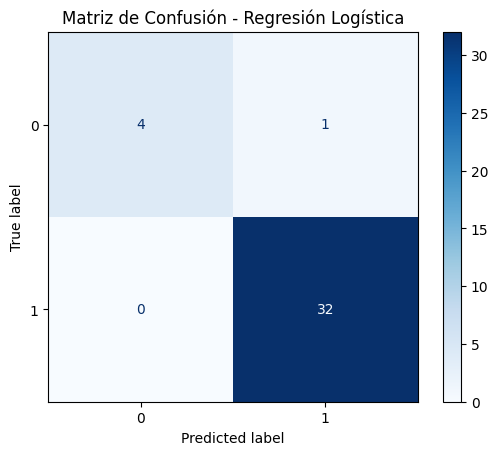

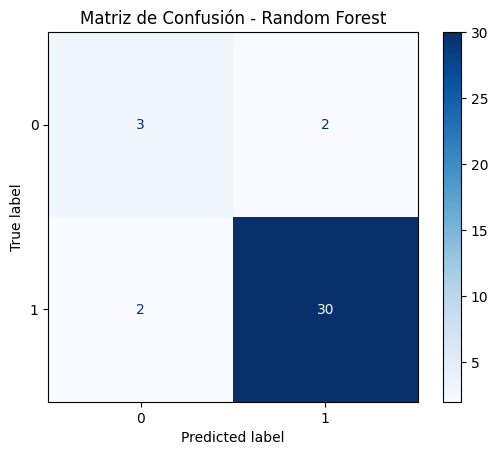

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Matriz de confusión para la regresión logística
cm_logreg = confusion_matrix(y_test, y_pred_logreg)
disp_logreg = ConfusionMatrixDisplay(confusion_matrix=cm_logreg)
disp_logreg.plot(cmap=plt.cm.Blues)
plt.title("Matriz de Confusión - Regresión Logística")
plt.show()

# Matriz de confusión para el random forest
cm_rf = confusion_matrix(y_test, y_pred_rf)
disp_rf = ConfusionMatrixDisplay(confusion_matrix=cm_rf)
disp_rf.plot(cmap=plt.cm.Blues)
plt.title("Matriz de Confusión - Random Forest")
plt.show()

* **Valor [0,0] (4):** Este valor representa las verdaderas negativas, es decir, los casos en los que el modelo predijo correctamente la clase 0 (no tiene potencial emprendedor).

* **Valor [0,1] (1):** Este valor indica las falsas positivas, lo que significa que el modelo predijo la clase 1 (tiene potencial emprendedor), pero en realidad era la clase 0.

* **Valor [1,0] (0):** Aquí se muestran las falsas negativas, es decir, los casos en los que el modelo predijo la clase 0 (no tiene potencial emprendedor) cuando en realidad era la clase 1. En este caso, el valor es 0, lo que indica que no hubo falsas negativas.

* **Valor [1,1] (32):** Representa las verdaderas positivas, es decir, los casos en los que el modelo predijo correctamente la clase 1 (tiene potencial emprendedor).

**Interpretación:**

* El modelo tuvo un total de 36 casos correctamente clasificados (4 verdaderas negativas + 32 verdaderas positivas).
* Hubo un solo caso en el que el modelo cometió un error (1 falsa positiva).
* La precisión del modelo es bastante alta, especialmente en la predicción de la clase 1, ya que no hubo falsas negativas.

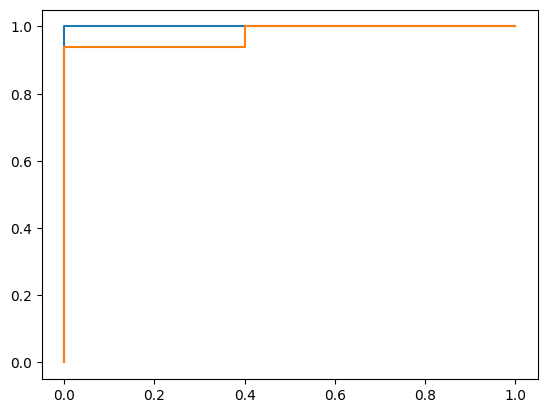

In [ ]:
from sklearn.metrics import roc_curve, auc

# Curva ROC para la regresión logística
fpr_logreg, tpr_logreg, _ = roc_curve(y_test, logreg.predict_proba(X_test)[:, 1], pos_label='Sí')
roc_auc_logreg = auc(fpr_logreg, tpr_logreg)
plt.plot(fpr_logreg, tpr_logreg, label=f"Regresión Logística (área = {roc_auc_logreg:.2f})")

# Curva ROC para el random forest
fpr_rf, tpr_rf, _ = roc_curve(y_test, rf.predict_proba(X_test)[:, 1], pos_label='Sí')
roc_auc_rf = auc(fpr_rf, tpr_rf)
plt.plot(fpr_rf, tpr_rf, label=f"Random Forest (área = {roc_auc_rf:.2f})")

**ROC (Receiver Operating Characteristic):**

*Ejes:*

* El eje X representa la Tasa de Falsos Positivos (False Positive Rate, FPR), es decir, el porcentaje de negativos que fueron clasificados incorrectamente como positivos.
* El eje Y representa la Tasa de Verdaderos Positivos (True Positive Rate, TPR), también conocida como sensibilidad o recall, que es el porcentaje de positivos que fueron clasificados correctamente.

*Curva ROC:*

* La curva ROC muestra la relación entre la TPR y la FPR para diferentes umbrales de decisión del modelo.
* En esta gráfica, la curva sube rápidamente hacia la esquina superior izquierda, lo cual indica que el modelo tiene un buen desempeño. La esquina superior izquierda representa el punto donde se maximiza la TPR y minimiza la FPR, lo que es ideal.

*Área bajo la curva (AUC):*

* Aunque la AUC no está indicada directamente en la gráfica, generalmente se calcula para cuantificar el desempeño del modelo. Una AUC cercana a 1 indica un modelo excelente, mientras que una AUC de 0.5 sugiere un modelo que no es mejor que una clasificación aleatoria.
* En nuestra curva ROC, la forma de la gráfica sugiere que la AUC sería alta, lo que indica un buen poder predictivo del modelo.

**Interpretación General:**

La curva muestra que el modelo tiene un rendimiento muy bueno, ya que es capaz de clasificar correctamente los verdaderos positivos mientras mantiene baja la tasa de falsos positivos en los diferentes umbrales. Esto sugiere que el modelo es efectivo para distinguir entre las dos clases (potencial emprendedor o no).